In [1]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC, LinearSVC, NuSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn. ensemble import RandomForestClassifier,AdaBoostClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_iris, load_digits, load_breast_cancer
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import struct
import re
import string

In [2]:
RANDOM_STATE = 42

In [3]:
kneighbors = KNeighborsClassifier()
svc = SVC(random_state = RANDOM_STATE)
linear_svc = LinearSVC(random_state = RANDOM_STATE)
nu_svc = NuSVC(random_state = RANDOM_STATE)
decision_tree = DecisionTreeClassifier(random_state = RANDOM_STATE)
random_forest = RandomForestClassifier(random_state = RANDOM_STATE)
ada_boost = AdaBoostClassifier(random_state = RANDOM_STATE)
gradient_boosting = GradientBoostingClassifier(random_state = RANDOM_STATE)
gaussian_nb = GaussianNB()
mlp = MLPClassifier(random_state = RANDOM_STATE)


Funcion para mostrar las matrices de confusion

In [4]:
def plot_confusion_matrix(matrix_conf):
  clasificadores = ["KNeighborsClassifier", "SVC", "LinearSVC", "NuSVC", "DecisionTreeClassifier", "RandomForestClassifier", "AdaBoostClassifier", "GradientBoostingClassifier", "GaussianNB", "MLPClassifier"]

  for i ,model_name in enumerate(clasificadores):
    disp = ConfusionMatrixDisplay(confusion_matrix=matrix_conf[i], display_labels=data.target_names)
    disp.plot(cmap=plt.cm.Blues, values_format='g')
    plt.title(f"Matriz de confusion para el modelo: {model_name}")
    plt.show()


In [5]:
def plot_confusion_matrix1(matrix_conf, labels):
  clasificadores = ["KNeighborsClassifier", "SVC", "LinearSVC", "NuSVC", "DecisionTreeClassifier", "RandomForestClassifier", "AdaBoostClassifier", "GradientBoostingClassifier", "GaussianNB", "MLPClassifier"]

  for i ,model_name in enumerate(clasificadores):
    disp = ConfusionMatrixDisplay(confusion_matrix=matrix_conf[i], display_labels=labels)
    disp.plot(cmap=plt.cm.Blues, values_format='g')
    plt.title(f"Matriz de confusion para el modelo: {model_name}")
    plt.show()

# Iris

In [6]:
data = load_iris()

Solo ploteamos los primeros 3 features debido a que no se pueden representar mas dimensiones.

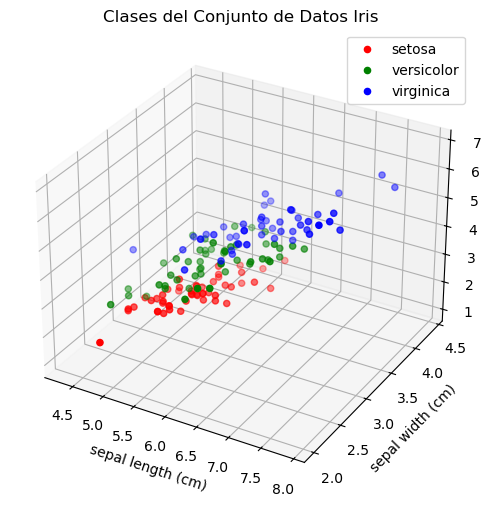

In [7]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

clases = data.target_names
colores = ['r', 'g', 'b']

for i, nombre_clase in enumerate(clases):
    indices = np.where(data.target == i)
    ax.scatter(data.data[indices, 0],
               data.data[indices, 1],
               data.data[indices, 2],
               c=colores[i],
               label=nombre_clase,
               marker='o')

ax.set_xlabel(data.feature_names[0])
ax.set_ylabel(data.feature_names[1])
ax.set_zlabel(data.feature_names[2])

plt.title("Clases del Conjunto de Datos Iris")
ax.legend()
plt.show()

In [8]:
X, y = data.data, data.target
x_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33)

In [9]:
results = {}
matrix_iris = []

In [10]:
kneighbors.fit(x_train, y_train)
y_pred = kneighbors.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["kneighbors"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_iris.append(confusion_matrix(y_test, y_pred))

In [11]:
svc.fit(x_train, y_train)
y_pred = svc.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["svc"] =  [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_iris.append(confusion_matrix(y_test, y_pred))

In [12]:
linear_svc.fit(x_train, y_train)
y_pred = linear_svc.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["linear_svc"] =  [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_iris.append(confusion_matrix(y_test, y_pred))

In [13]:
nu_svc.fit(x_train, y_train)
y_pred = nu_svc.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["nu_svc"] =  [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_iris.append(confusion_matrix(y_test, y_pred))

In [14]:
decision_tree.fit(x_train, y_train)
y_pred = decision_tree.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["decision_tree"] =  [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_iris.append(confusion_matrix(y_test, y_pred))

In [15]:
random_forest.fit(x_train, y_train)
y_pred = random_forest.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["random_forest"] =  [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_iris.append(confusion_matrix(y_test, y_pred))

In [16]:
ada_boost.fit(x_train, y_train)
y_pred = ada_boost.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["ada_boost"] =  [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_iris.append(confusion_matrix(y_test, y_pred))

In [17]:
gradient_boosting.fit(x_train, y_train)
y_pred = gradient_boosting.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["gradient_boosting"] =  [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_iris.append(confusion_matrix(y_test, y_pred))

In [18]:
gaussian_nb.fit(x_train, y_train)
y_pred = gaussian_nb.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["gaussian_nb"] =  [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_iris.append(confusion_matrix(y_test, y_pred))

In [19]:
mlp.fit(x_train, y_train)
y_pred = mlp.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["mlp"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_iris.append(confusion_matrix(y_test, y_pred))

/opt/anaconda3/envs/mlescom/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


In [20]:
results

{'kneighbors': [0.9642105263157894, 0.96, 0.9598611111111112, 0.96],
 'svc': [1.0, 1.0, 1.0, 1.0],
 'linear_svc': [0.9811111111111112, 0.98, 0.979982683982684, 0.98],
 'nu_svc': [1.0, 1.0, 1.0, 1.0],
 'decision_tree': [0.9811111111111112, 0.98, 0.979982683982684, 0.98],
 'random_forest': [0.9811111111111112, 0.98, 0.979982683982684, 0.98],
 'ada_boost': [0.9409722222222223, 0.94, 0.939948051948052, 0.94],
 'gradient_boosting': [0.9811111111111112, 0.98, 0.979982683982684, 0.98],
 'gaussian_nb': [0.9811111111111112, 0.98, 0.979982683982684, 0.98],
 'mlp': [0.9642105263157894, 0.96, 0.9598611111111112, 0.96]}

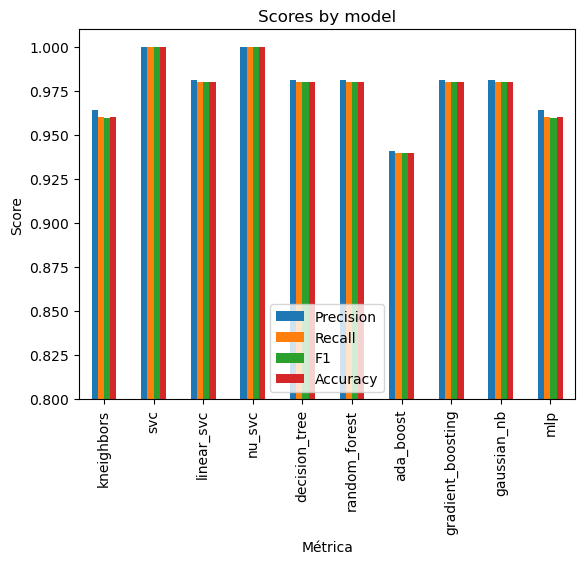

In [21]:
metrics = ["Precision", "Recall", "F1", "Accuracy"]
df = pd.DataFrame.from_dict(results, orient="index" ,columns=metrics)

df.plot(kind="bar")
plt.ylabel("Score")
plt.xlabel("Métrica")
plt.ylim(0.8, 1.01)
plt.title("Scores by model")
plt.show()

Mostramos las matrices de confusion para compararlas

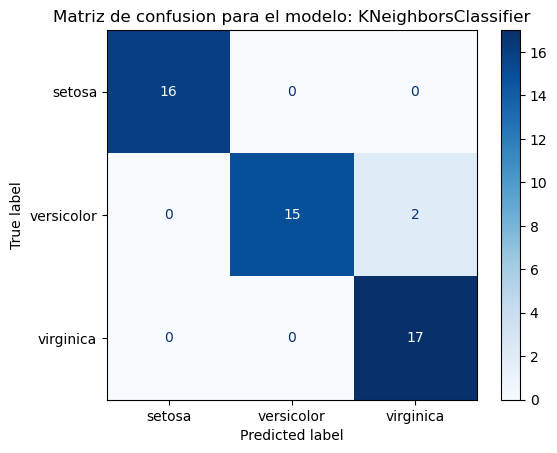

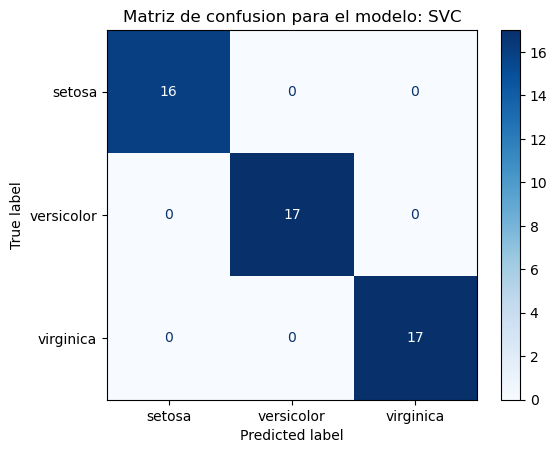

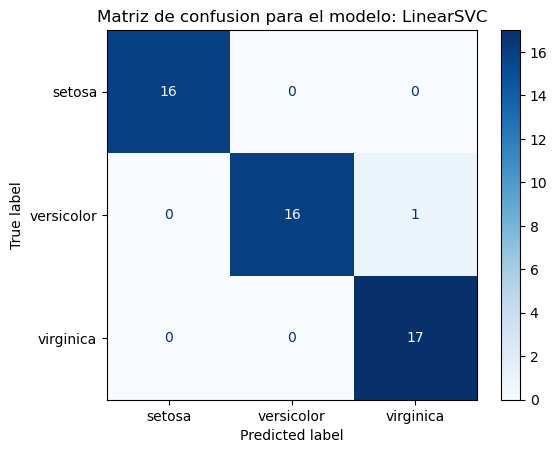

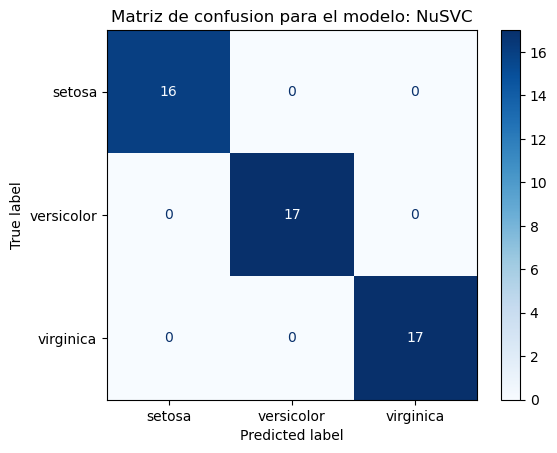

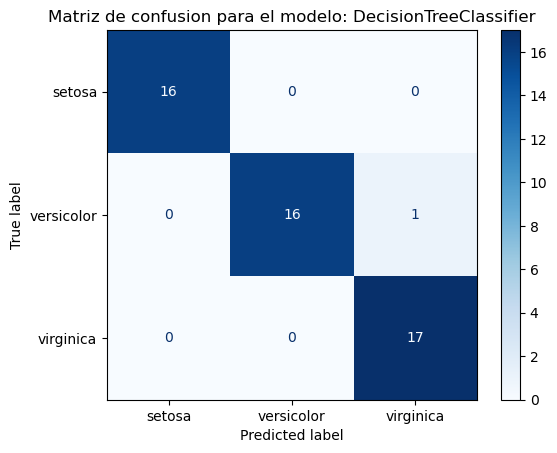

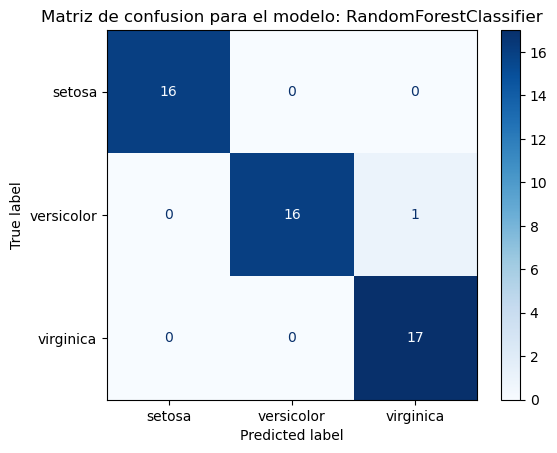

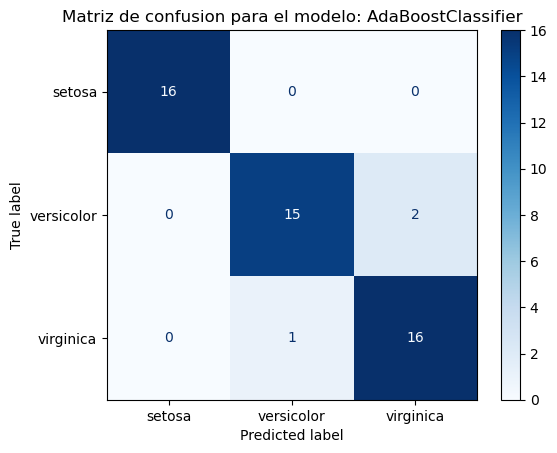

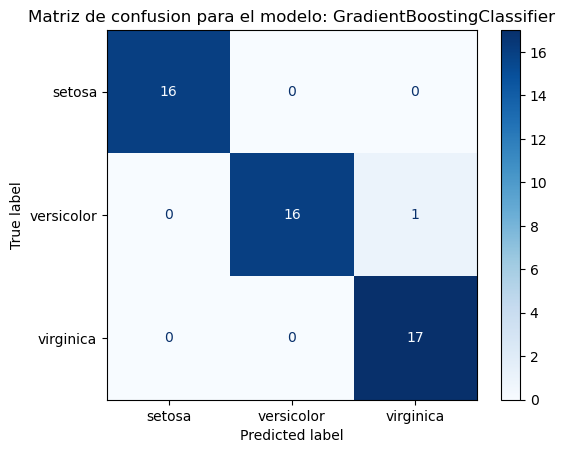

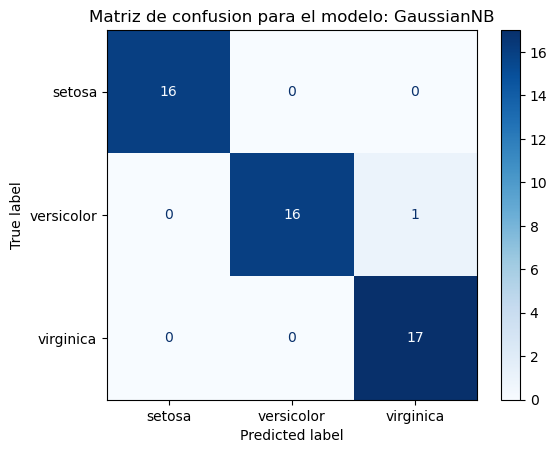

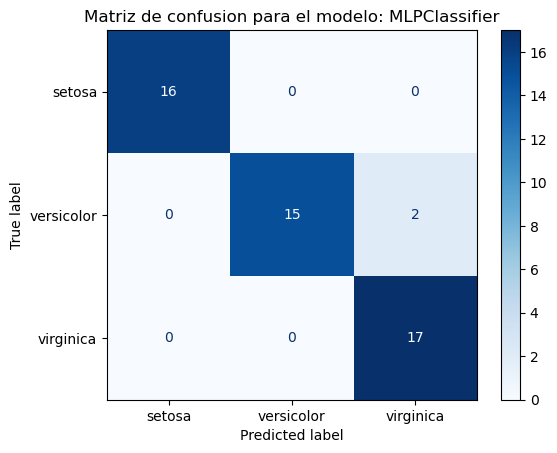

In [22]:
plot_confusion_matrix1(matrix_iris, data.target_names)

# Digits

In [23]:
data = load_digits()

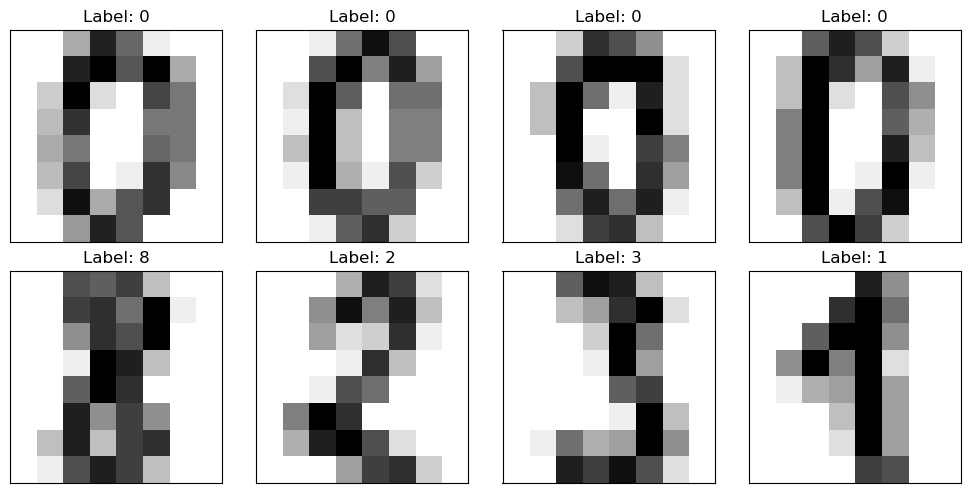

In [24]:
indices = [0, 10, 20, 30, 40, 50, 60, 70]
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
axes = axes.ravel()

for i, ax in enumerate(axes):
    if i < len(indices):
        image = data.data[indices[i]].reshape((8, 8))
        ax.imshow(image, cmap=plt.cm.gray_r, interpolation='nearest')
        ax.set_title(f'Label: {data.target[indices[i]]}')
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()

In [25]:
X, y = data.data, data.target
x_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33)

In [26]:
results = {}
matrix_digits = []

In [27]:
kneighbors.fit(x_train, y_train)
y_pred = kneighbors.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["kneighbors"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
matrix_digits.append(confusion_matrix(y_test, y_pred))

In [28]:
svc.fit(x_train, y_train)
y_pred = svc.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["svc"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
matrix_digits.append(confusion_matrix(y_test, y_pred))

In [29]:
linear_svc.fit(x_train, y_train)
y_pred = linear_svc.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["linear_svc"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
matrix_digits.append(confusion_matrix(y_test, y_pred))

In [30]:
nu_svc.fit(x_train, y_train)
y_pred = nu_svc.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["nu_svc"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
matrix_digits.append(confusion_matrix(y_test, y_pred))

In [31]:
decision_tree.fit(x_train, y_train)
y_pred = decision_tree.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["decision_tree"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
matrix_digits.append(confusion_matrix(y_test, y_pred))

In [32]:
random_forest.fit(x_train, y_train)
y_pred = random_forest.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["random_forest"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
matrix_digits.append(confusion_matrix(y_test, y_pred))

In [33]:
ada_boost.fit(x_train, y_train)
y_pred = ada_boost.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["ada_boost"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
matrix_digits.append(confusion_matrix(y_test, y_pred))

In [34]:
gradient_boosting.fit(x_train, y_train)
y_pred = gradient_boosting.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["gradient_boosting"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
matrix_digits.append(confusion_matrix(y_test, y_pred))

In [35]:
gaussian_nb.fit(x_train, y_train)
y_pred = gaussian_nb.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["gaussian_nb"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
matrix_digits.append(confusion_matrix(y_test, y_pred))

In [36]:
mlp.fit(x_train, y_train)
y_pred = mlp.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["mlp"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
matrix_digits.append(confusion_matrix(y_test, y_pred))

In [37]:
results

{'kneighbors': [0.9866909158771443,
  0.9865319865319865,
  0.9865076899359753,
  0.9865319865319865],
 'svc': [0.9851965713337648,
  0.9848484848484849,
  0.9848425014374013,
  0.9848484848484849],
 'linear_svc': [0.9501370243857801,
  0.9478114478114478,
  0.9481590015233702,
  0.9478114478114478],
 'nu_svc': [0.9616038465930816,
  0.9595959595959596,
  0.9596822027972279,
  0.9595959595959596],
 'decision_tree': [0.8509171467119352,
  0.8468013468013468,
  0.8474393671480157,
  0.8468013468013468],
 'random_forest': [0.9716802741206316,
  0.9713804713804713,
  0.971207272378716,
  0.9713804713804713],
 'ada_boost': [0.7089950866076273,
  0.702020202020202,
  0.6943409613028315,
  0.702020202020202],
 'gradient_boosting': [0.9653087184124531,
  0.9646464646464646,
  0.9648081218083439,
  0.9646464646464646],
 'gaussian_nb': [0.8383915964917878,
  0.7895622895622896,
  0.7914008748465203,
  0.7895622895622896],
 'mlp': [0.9801137680420707,
  0.9797979797979798,
  0.9797581489475977,
 

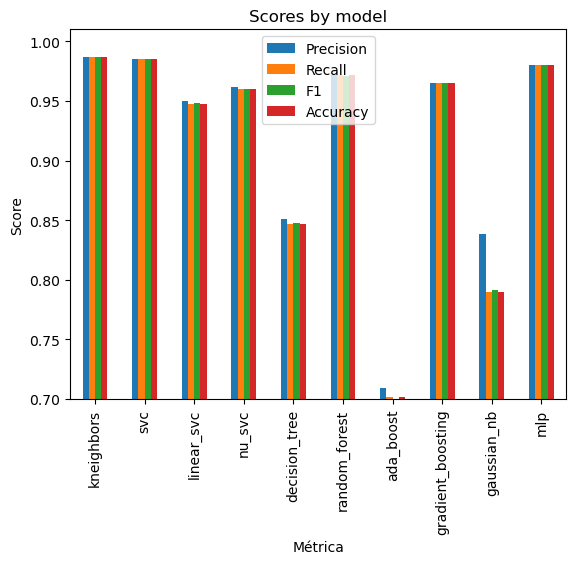

In [38]:
metrics = ["Precision", "Recall", "F1", "Accuracy"]

df = pd.DataFrame.from_dict(results, orient="index" ,columns=metrics)

df.plot(kind="bar")
plt.ylabel("Score")
plt.xlabel("Métrica")
plt.ylim(0.7, 1.01)
plt.title("Scores by model")
plt.show()

Se comparan todas las matrices de confusion para el dataset de Digits

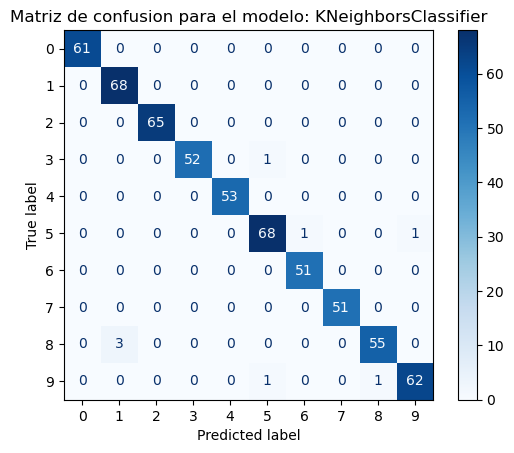

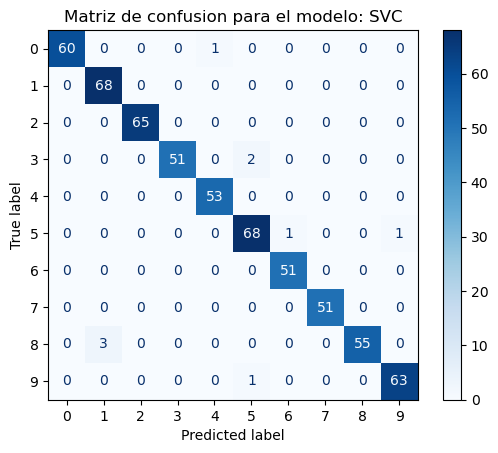

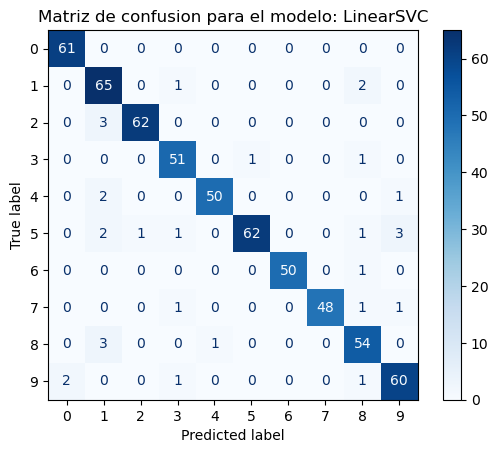

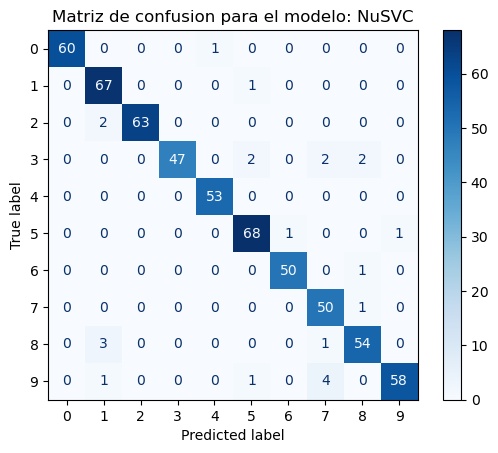

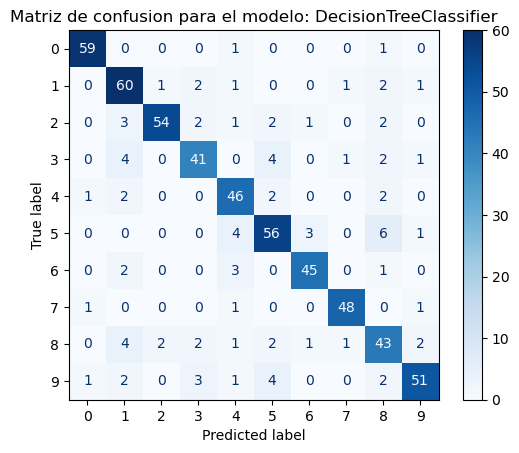

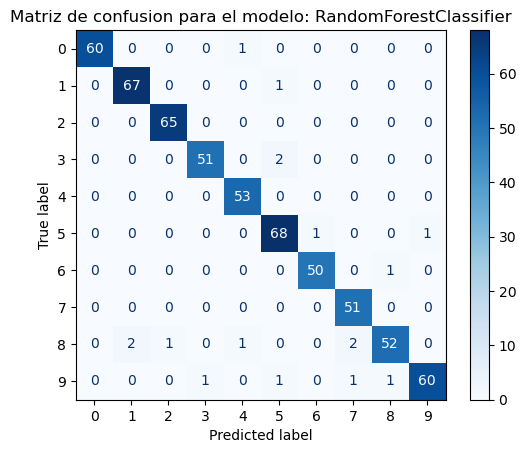

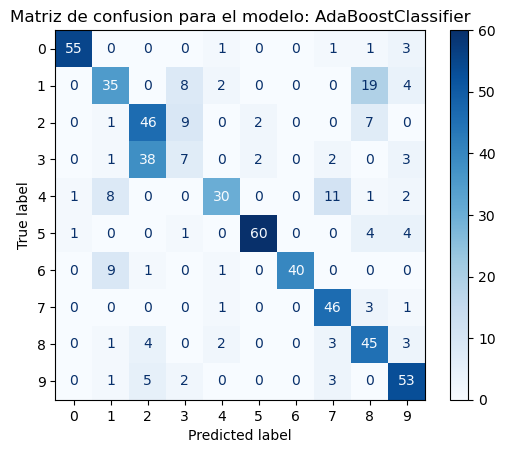

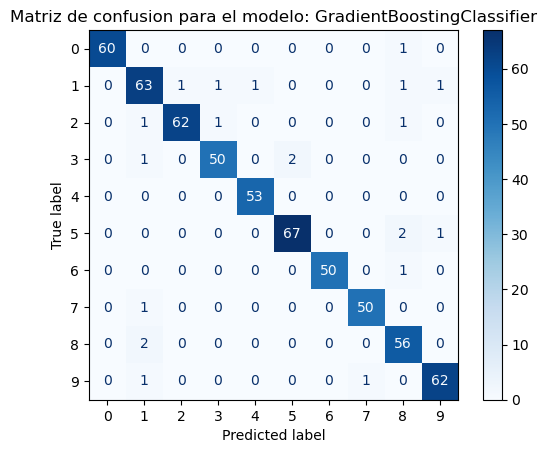

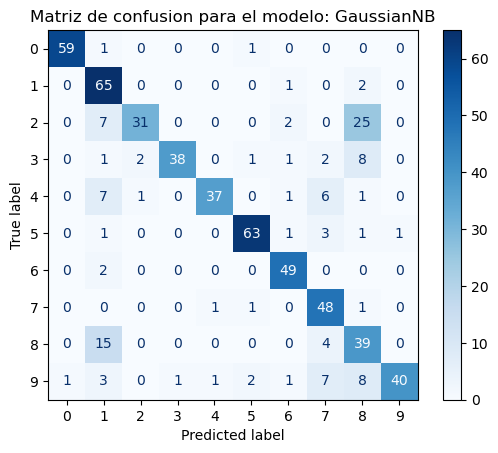

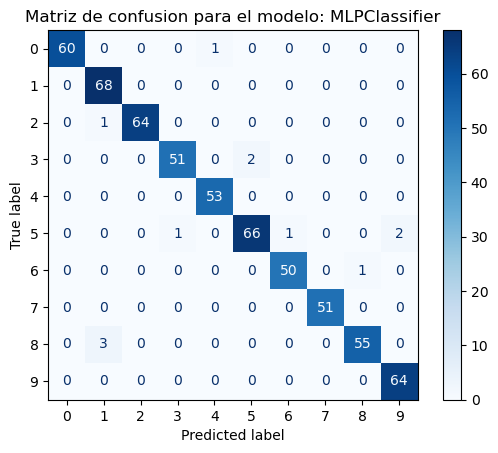

In [39]:
plot_confusion_matrix(matrix_digits)

# Breast Cancer Wisconsin

In [40]:
data = load_breast_cancer()

Solo ploteamos los primeros 3 features debido a que no se pueden representar mas dimensiones.

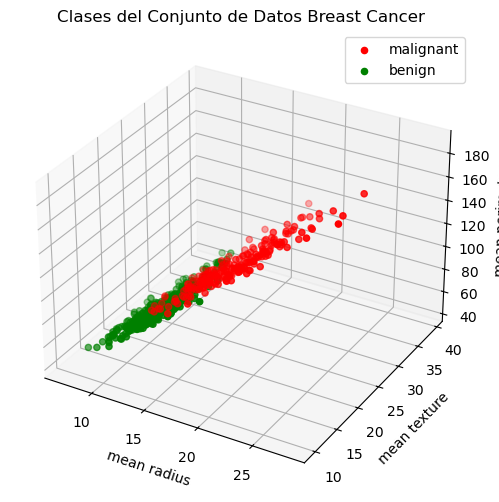

In [41]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

clases = data.target_names
colores = ['r', 'g', 'b']

for i, nombre_clase in enumerate(clases):
    indices = np.where(data.target == i)
    ax.scatter(data.data[indices, 0],
               data.data[indices, 1],
               data.data[indices, 2],
               c=colores[i],
               label=nombre_clase,
               marker='o')

ax.set_xlabel(data.feature_names[0])
ax.set_ylabel(data.feature_names[1])
ax.set_zlabel(data.feature_names[2])

plt.title("Clases del Conjunto de Datos Breast Cancer")
ax.legend()
plt.show()

In [42]:
X, y = data.data, data.target
x_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33)

In [43]:
results = {}
matrix_breast_cancer = []

In [44]:
kneighbors.fit(x_train, y_train)
y_pred = kneighbors.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["kneighbors"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]

matrix_breast_cancer.append(confusion_matrix(y_test, y_pred))

In [45]:
svc.fit(x_train, y_train)
y_pred = svc.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["svc"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
matrix_breast_cancer.append(confusion_matrix(y_test, y_pred))

In [46]:
linear_svc.fit(x_train, y_train)
y_pred = linear_svc.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["linear_svc"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
matrix_breast_cancer.append(confusion_matrix(y_test, y_pred))

In [47]:
nu_svc.fit(x_train, y_train)
y_pred = nu_svc.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["nu_svc"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
matrix_breast_cancer.append(confusion_matrix(y_test, y_pred))

In [48]:
decision_tree.fit(x_train, y_train)
y_pred = decision_tree.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["decision_tree"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
matrix_breast_cancer.append(confusion_matrix(y_test, y_pred))

In [49]:
random_forest.fit(x_train, y_train)
y_pred = random_forest.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["random_forest"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
matrix_breast_cancer.append(confusion_matrix(y_test, y_pred))

In [50]:
ada_boost.fit(x_train, y_train)
y_pred = ada_boost.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["ada_boost"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
matrix_breast_cancer.append(confusion_matrix(y_test, y_pred))

In [51]:
gradient_boosting.fit(x_train, y_train)
y_pred = gradient_boosting.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["gradient_boosting"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
matrix_breast_cancer.append(confusion_matrix(y_test, y_pred))

In [52]:
gaussian_nb.fit(x_train, y_train)
y_pred = gaussian_nb.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["gaussian_nb"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
matrix_breast_cancer.append(confusion_matrix(y_test, y_pred))

In [53]:
mlp.fit(x_train, y_train)
y_pred = mlp.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["mlp"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
matrix_breast_cancer.append(confusion_matrix(y_test, y_pred))

/opt/anaconda3/envs/mlescom/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


In [54]:
results

{'kneighbors': [0.9306627812595639,
  0.9308510638297872,
  0.9307282568703948,
  0.9308510638297872],
 'svc': [0.9258976063829787,
  0.925531914893617,
  0.9246524822695036,
  0.925531914893617],
 'linear_svc': [0.9680958304735758,
  0.9680851063829787,
  0.9679693425412159,
  0.9680851063829787],
 'nu_svc': [0.9130373111316683,
  0.9042553191489362,
  0.9005982278909646,
  0.9042553191489362],
 'decision_tree': [0.9483952398124774,
  0.9468085106382979,
  0.9471474760116813,
  0.9468085106382979],
 'random_forest': [0.962693438718348,
  0.9627659574468085,
  0.9626998306225203,
  0.9627659574468085],
 'ada_boost': [0.9736616008105371,
  0.973404255319149,
  0.973256515093542,
  0.973404255319149],
 'gradient_boosting': [0.9680851063829787,
  0.9680851063829787,
  0.9680851063829787,
  0.9680851063829787],
 'gaussian_nb': [0.9521337386018236,
  0.9521276595744681,
  0.9518617271683758,
  0.9521276595744681],
 'mlp': [0.9258976063829787,
  0.925531914893617,
  0.9246524822695036,
  0.9

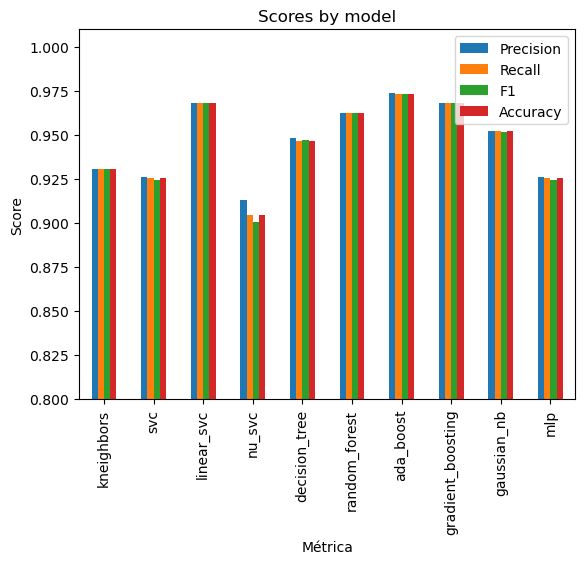

In [55]:
metrics = ["Precision", "Recall", "F1", "Accuracy"]

df = pd.DataFrame.from_dict(results, orient="index" ,columns=metrics)

df.plot(kind="bar")
plt.ylabel("Score")
plt.xlabel("Métrica")
plt.ylim(0.8, 1.01)
plt.title("Scores by model")
plt.show()

Se comparan las matrices de confusion del dataset Breast_Cancer


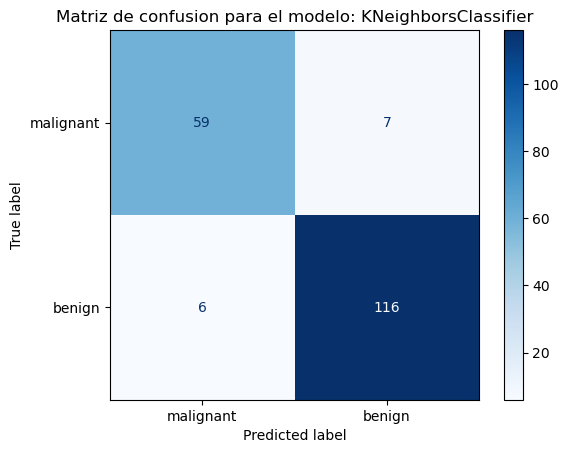

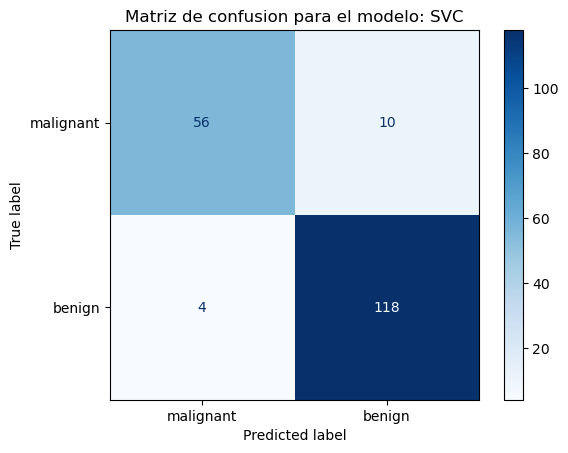

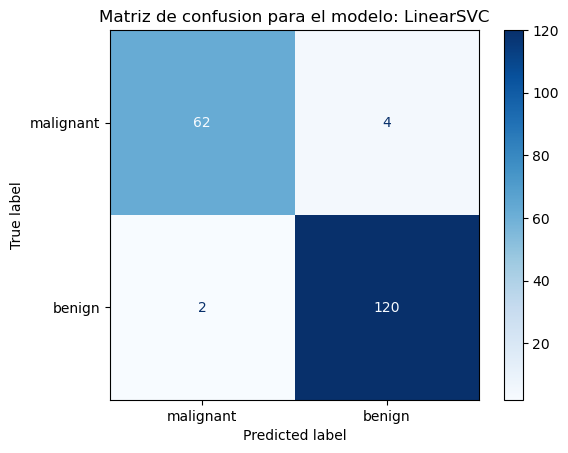

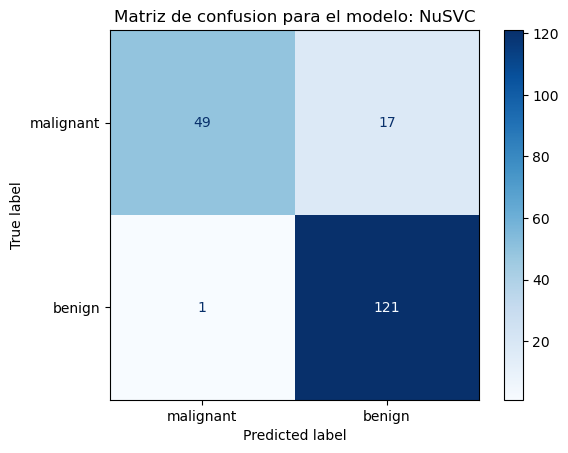

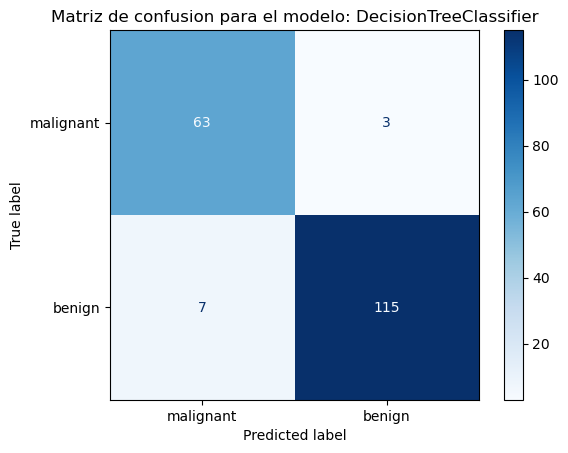

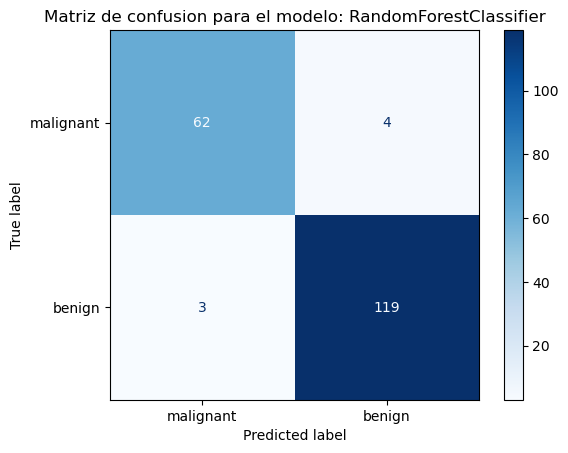

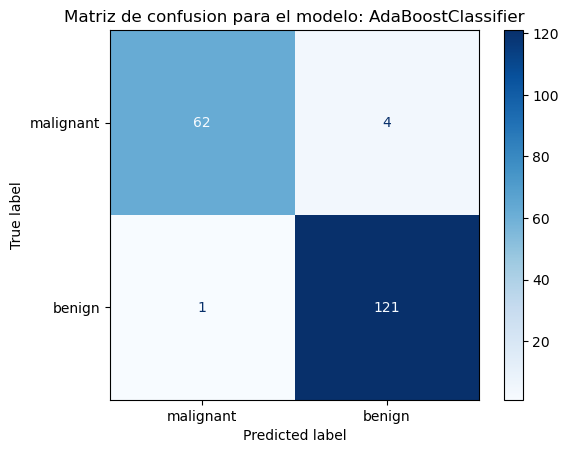

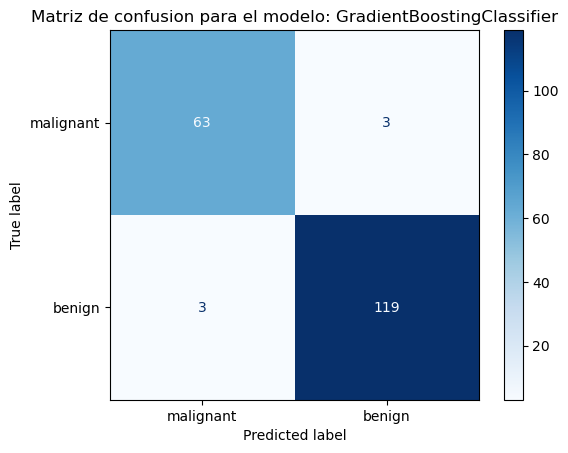

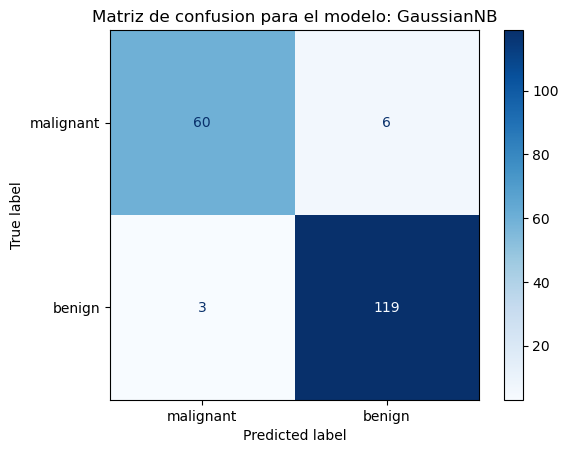

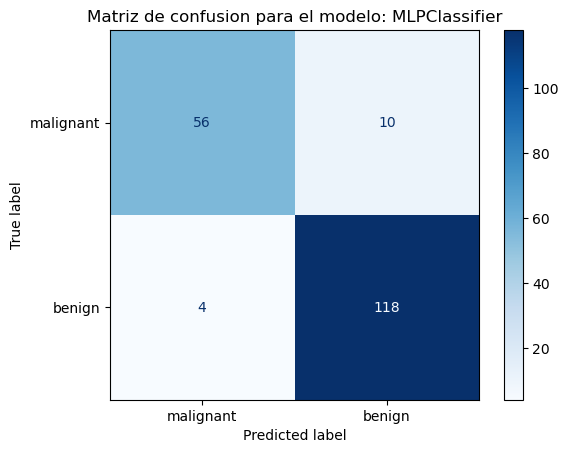

In [56]:
plot_confusion_matrix(matrix_breast_cancer)

# Heart Disease

In [57]:
#subi el dataset a google para no tener que estarlo cargando de manera manual cada que se descarga o clona de nuevo el proyecto
path = "https://docs.google.com/spreadsheets/d/e/2PACX-1vTY-qdxuY-XTMP8_svbSzsBJGTa8AlC2Qumq0j3JXEk2-sLxwcwlAh6F1D2OpjS9iK1HRDZfA1pSRqt/pub?gid=1675467064&single=true&output=csv"

data = pd.read_csv(path)

In [58]:
data.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

Solo ploteamos los primeros 3 features debido a que no se pueden representar mas dimensiones.

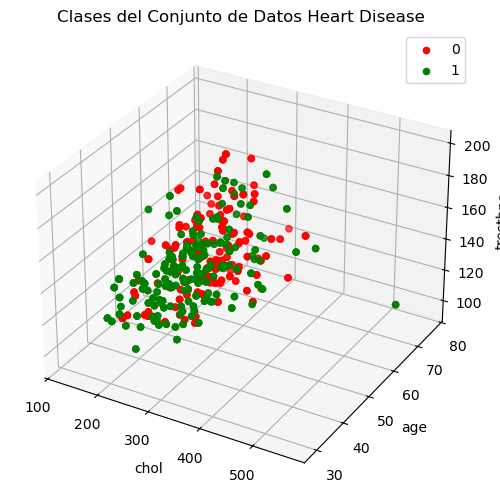

In [59]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

clases = data["target"].unique()
colores = ['r', 'g', 'b']

for i, nombre_clase in enumerate(clases):
    indices = np.where(data["target"] == i)[0]
    ax.scatter(data.iloc[indices, 4],
               data.iloc[indices, 0],
               data.iloc[indices, 3],
               c=colores[i],
               label=nombre_clase,
               marker='o')

ax.set_xlabel(data.columns[4])
ax.set_ylabel(data.columns[0])
ax.set_zlabel(data.columns[3])

plt.title("Clases del Conjunto de Datos Heart Disease")
ax.legend()
plt.show()

In [60]:
X, y = data.drop("target", axis=1), data["target"]
x_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33)

In [61]:
results = {}
matrix_heart_disease = []

In [62]:
kneighbors.fit(x_train, y_train)
y_pred = kneighbors.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["kneighbors"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]

matrix_heart_disease.append(confusion_matrix(y_test, y_pred))

In [63]:
svc.fit(x_train, y_train)
y_pred = svc.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["svc"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
matrix_heart_disease.append(confusion_matrix(y_test, y_pred))

In [64]:
linear_svc.fit(x_train, y_train)
y_pred = linear_svc.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["linear_svc"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
matrix_heart_disease.append(confusion_matrix(y_test, y_pred))

In [65]:
nu_svc.fit(x_train, y_train)
y_pred = nu_svc.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["nu_svc"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
matrix_heart_disease.append(confusion_matrix(y_test, y_pred))

In [66]:
decision_tree.fit(x_train, y_train)
y_pred = decision_tree.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["decision_tree"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
matrix_heart_disease.append(confusion_matrix(y_test, y_pred))

In [67]:
random_forest.fit(x_train, y_train)
y_pred = random_forest.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["random_forest"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
matrix_heart_disease.append(confusion_matrix(y_test, y_pred))

In [68]:
ada_boost.fit(x_train, y_train)
y_pred = ada_boost.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["ada_boost"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
matrix_heart_disease.append(confusion_matrix(y_test, y_pred))

In [69]:
gradient_boosting.fit(x_train, y_train)
y_pred = gradient_boosting.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["gradient_boosting"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
matrix_heart_disease.append(confusion_matrix(y_test, y_pred))

In [70]:
gaussian_nb.fit(x_train, y_train)
y_pred = gaussian_nb.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["gaussian_nb"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
matrix_heart_disease.append(confusion_matrix(y_test, y_pred))

In [71]:
mlp.fit(x_train, y_train)
y_pred = mlp.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["mlp"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
matrix_heart_disease.append(confusion_matrix(y_test, y_pred))

In [72]:
results

{'kneighbors': [0.7370987259325303,
  0.7374631268436578,
  0.7367569669246506,
  0.7374631268436578],
 'svc': [0.6955180983698799,
  0.696165191740413,
  0.6953479504858318,
  0.696165191740413],
 'linear_svc': [0.8375262176724277,
  0.831858407079646,
  0.829988854316813,
  0.831858407079646],
 'nu_svc': [0.8651193410649102,
  0.8495575221238938,
  0.8464505328799659,
  0.8495575221238938],
 'decision_tree': [1.0, 1.0, 1.0, 1.0],
 'random_forest': [1.0, 1.0, 1.0, 1.0],
 'ada_boost': [0.8356413071632233,
  0.8348082595870207,
  0.8341623428903234,
  0.8348082595870207],
 'gradient_boosting': [0.9587020648967551,
  0.9587020648967551,
  0.9587020648967551,
  0.9587020648967551],
 'gaussian_nb': [0.8321401603614457,
  0.831858407079646,
  0.831406147356237,
  0.831858407079646],
 'mlp': [0.8009957703173043,
  0.7876106194690266,
  0.7871964609165599,
  0.7876106194690266]}

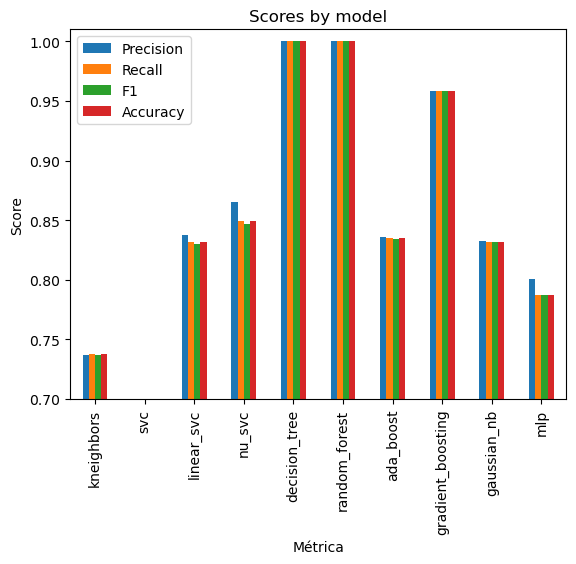

In [73]:
metrics = ["Precision", "Recall", "F1", "Accuracy"]

df = pd.DataFrame.from_dict(results, orient="index" ,columns=metrics)

df.plot(kind="bar")
plt.ylabel("Score")
plt.xlabel("Métrica")
plt.ylim(0.7, 1.01)
plt.title("Scores by model")
plt.show()

Comparamos las matrices de confusion del dataset Heart_Disease

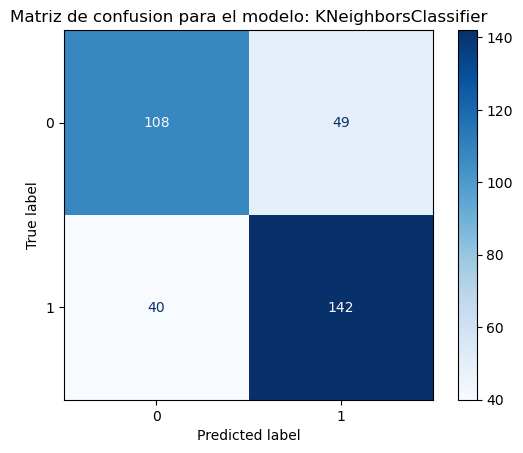

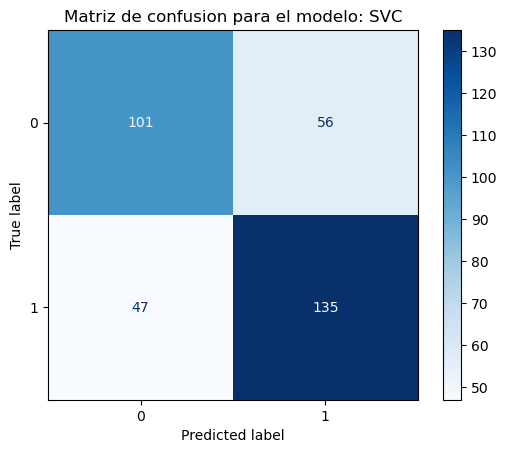

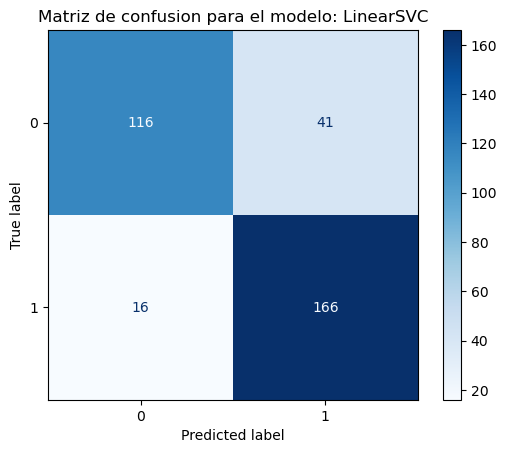

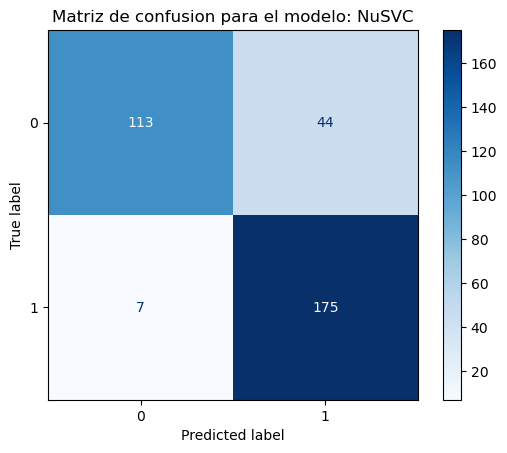

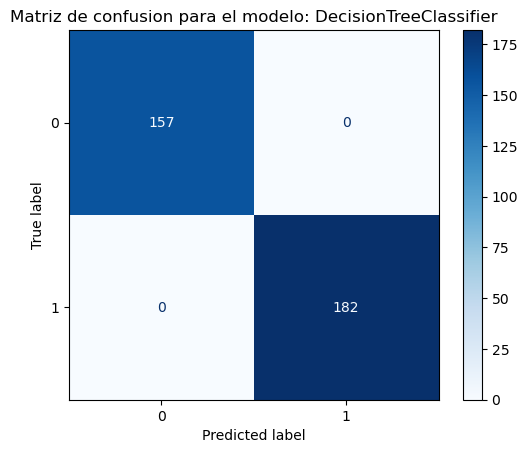

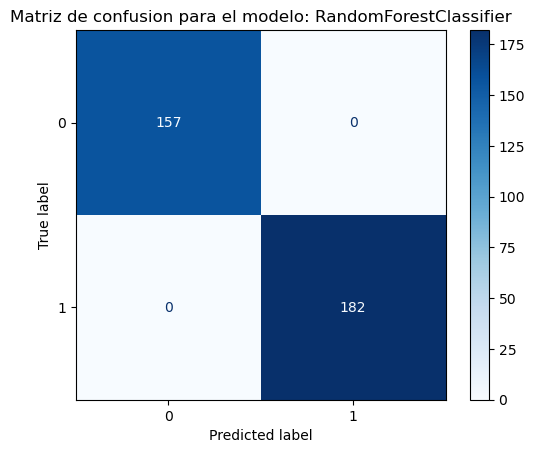

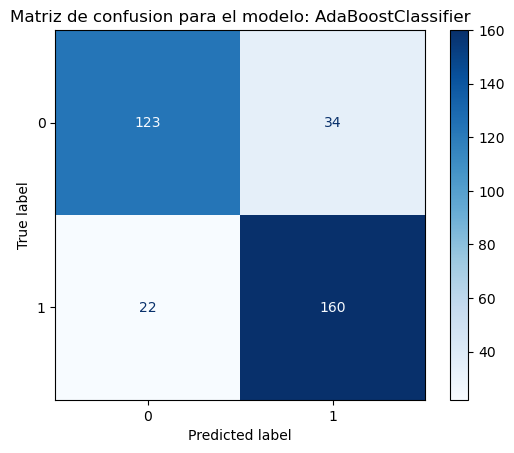

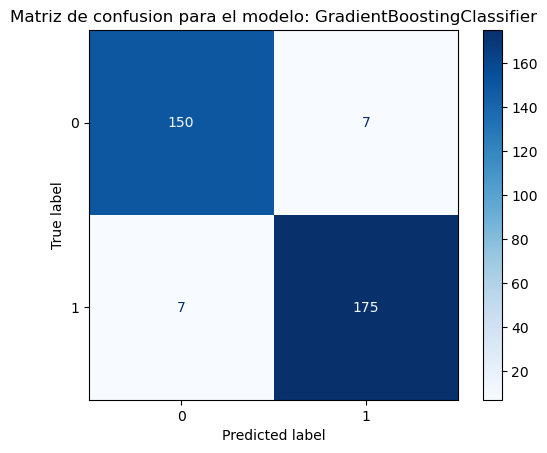

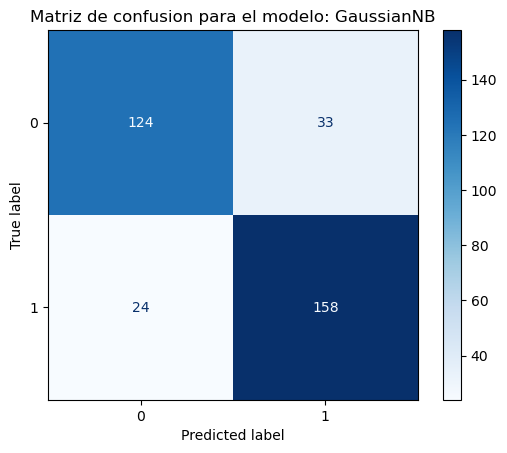

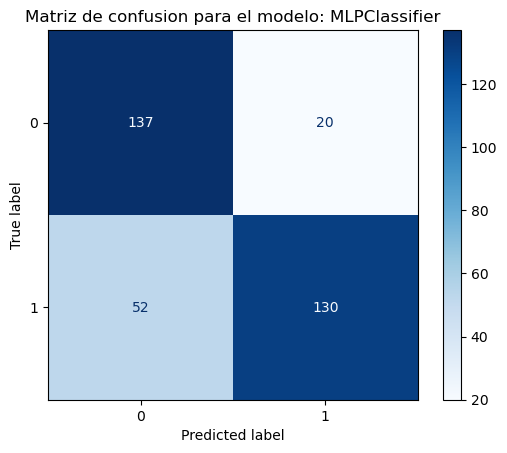

In [74]:
plot_confusion_matrix1(matrix_heart_disease,data['target'].unique())

# Adult Census Income

In [75]:
#Subi el archivo a drive igual para evitar tener que estarlo agregando de manera manual xd
path = "https://docs.google.com/spreadsheets/d/e/2PACX-1vR_SeQ-mGxVivulS2kZiI-IAE2RsrlBjKp0gBwxsWRdUPsOyjPQZuLz1h2DzB5zwiebqGtYauNQ55dZ/pub?gid=1137038700&single=true&output=csv"

data = pd.read_csv(path)

In [76]:
data

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,22,Private,310152,Some-college,10,Never-married,Protective-serv,Not-in-family,White,Male,0,0,40,United-States,<=50K
32557,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32558,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32559,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K


Solo ploteamos los primeros 3 features debido a que no se pueden representar mas dimensiones.

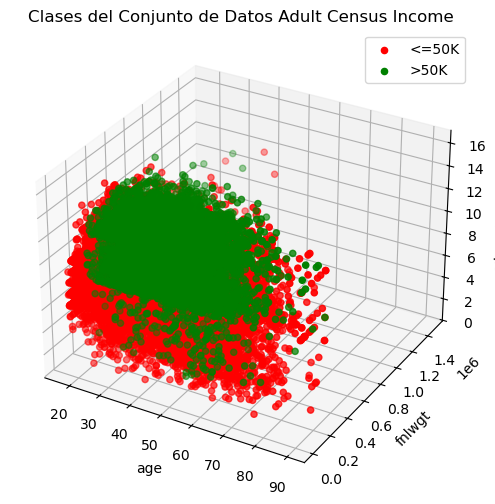

In [77]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

clases = data["income"].unique()
colores = ['r', 'g', 'b']

for i, nombre_clase in enumerate(clases):
    indices = np.where(data["income"] == nombre_clase)[0]
    ax.scatter(data.iloc[indices, 0],
               data.iloc[indices, 2],
               data.iloc[indices, 4],
               c=colores[i],
               label=nombre_clase,
               marker='o')

ax.set_xlabel(data.columns[0])
ax.set_ylabel(data.columns[2])
ax.set_zlabel(data.columns[4])

plt.title("Clases del Conjunto de Datos Adult Census Income")
ax.legend()
plt.show()

In [78]:
X = pd.get_dummies(X, columns=X.select_dtypes(include='object').columns, drop_first=True)

# Split the data again after one-hot encoding
x_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33)

In [79]:
results = {}
matrix_adult_census = []

In [80]:
results = {}
matrix_adult_census = []

In [81]:
kneighbors.fit(x_train, y_train)
y_pred = kneighbors.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["kneighbors"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_adult_census.append(cm)

In [82]:
svc.fit(x_train, y_train)
y_pred = svc.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["svc"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_adult_census.append(cm)

In [83]:
linear_svc.fit(x_train, y_train)
y_pred = linear_svc.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["linear_svc"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_adult_census.append(cm)

In [84]:
nu_svc = NuSVC(nu=0.1, random_state=RANDOM_STATE)
nu_svc.fit(x_train, y_train)
y_pred = nu_svc.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["nu_svc"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_adult_census.append(cm)

In [85]:
decision_tree.fit(x_train, y_train)
y_pred = decision_tree.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["decision_tree"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_adult_census.append(cm)

In [86]:
random_forest.fit(x_train, y_train)
y_pred = random_forest.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["random_forest"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_adult_census.append(cm)


In [87]:
ada_boost.fit(x_train, y_train)
y_pred = ada_boost.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["ada_boost"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_adult_census.append(cm)

In [88]:
gradient_boosting.fit(x_train, y_train)
y_pred = gradient_boosting.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["gradient_boosting"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_adult_census.append(cm)

In [89]:
gaussian_nb.fit(x_train, y_train)
y_pred = gaussian_nb.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["gaussian_nb"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_adult_census.append(cm)

In [90]:
mlp.fit(x_train, y_train)
y_pred = mlp.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["mlp"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_adult_census.append(cm)

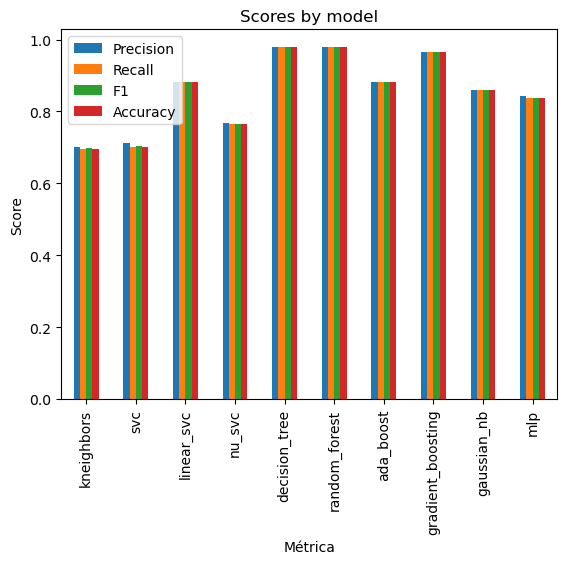

In [91]:
metrics = ["Precision", "Recall", "F1", "Accuracy"]

df = pd.DataFrame.from_dict(results, orient="index" ,columns=metrics)

df.plot(kind="bar")
plt.ylabel("Score")
plt.xlabel("Métrica")
plt.title("Scores by model")
plt.show()

Comparamos las matrices de confusion del dataset Adult_census_income

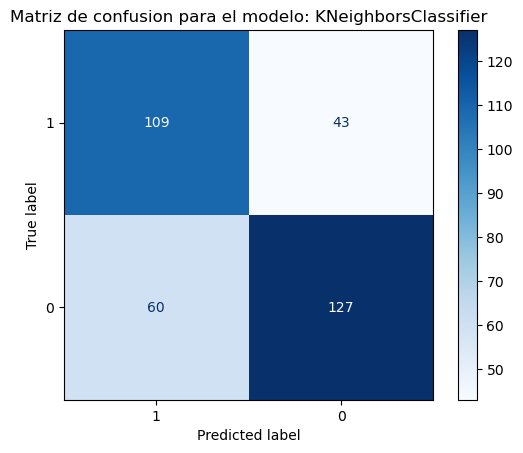

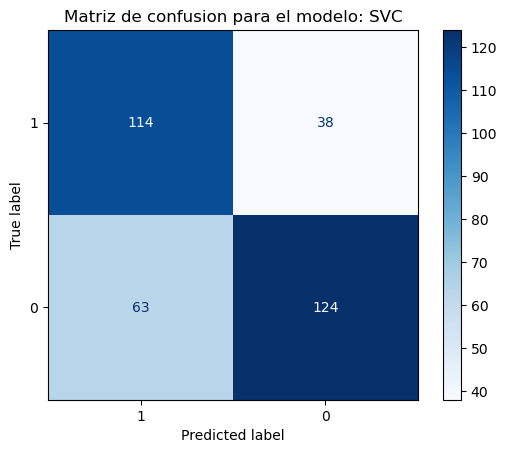

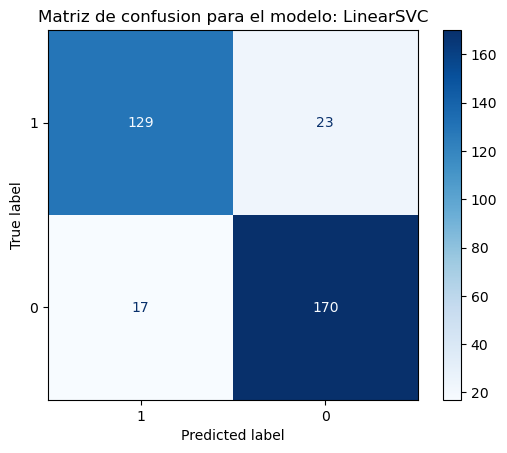

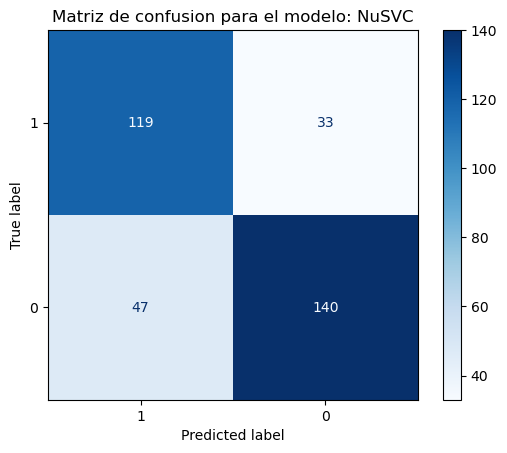

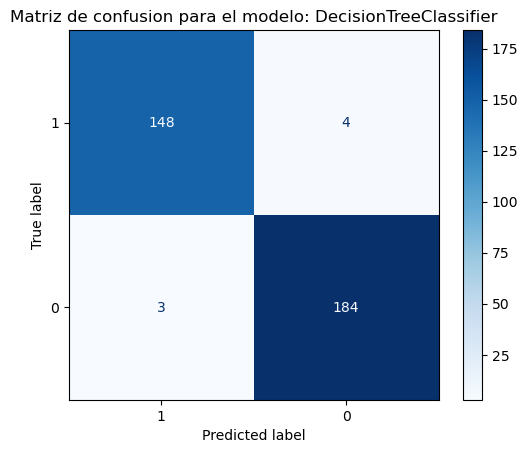

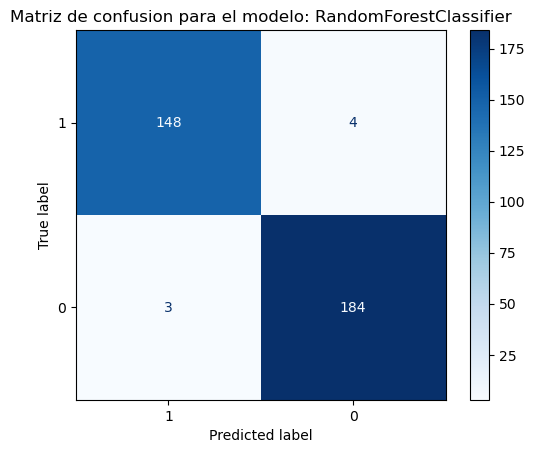

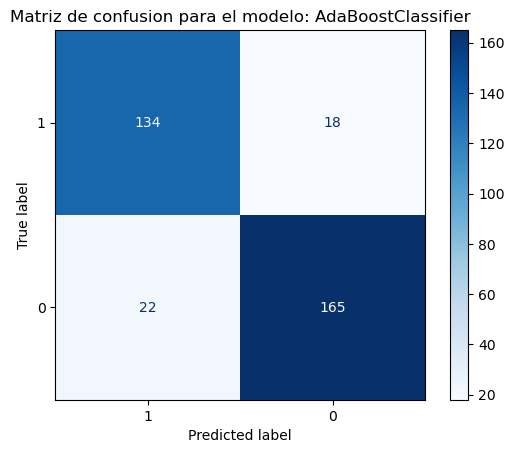

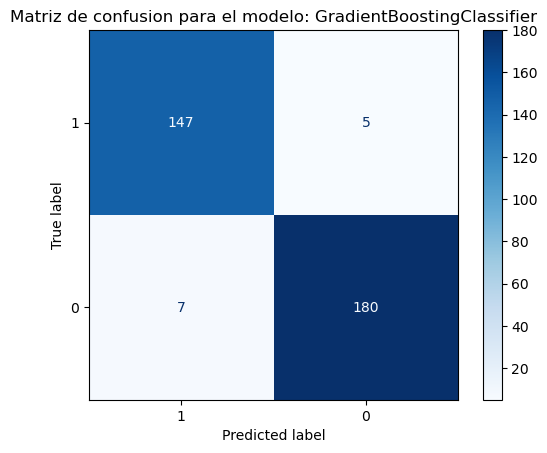

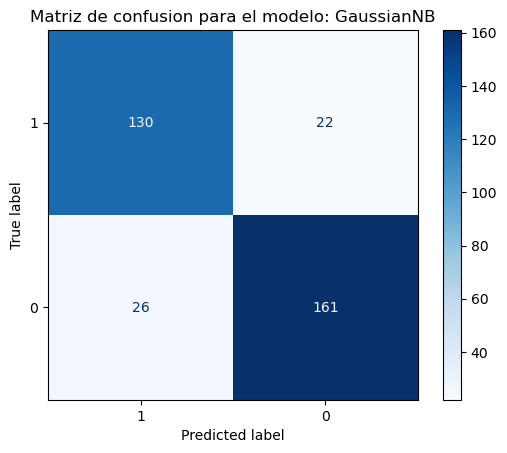

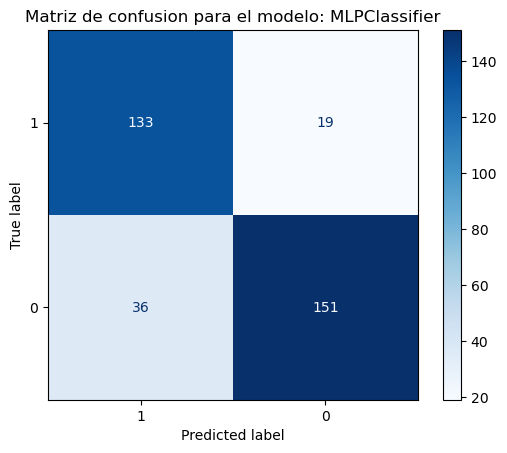

In [92]:
plot_confusion_matrix1(matrix_adult_census,y_test.unique())

# Bank Marketing Dataset

In [93]:
#se subio a google sheets el archivo para un mejor manejo
path = "https://docs.google.com/spreadsheets/d/e/2PACX-1vS-L3WkOw0VZhdWbx9AORnfSv7Y1oQcE2XFvnkMQIZBfF8OfVVcX5KAJGBa4khLoEVTFfQXm1B91yzM/pub?gid=582355029&single=true&output=csv"
data = pd.read_csv(path)

Solo ploteamos los primeros 3 features debido a que no se pueden representar mas dimensiones.

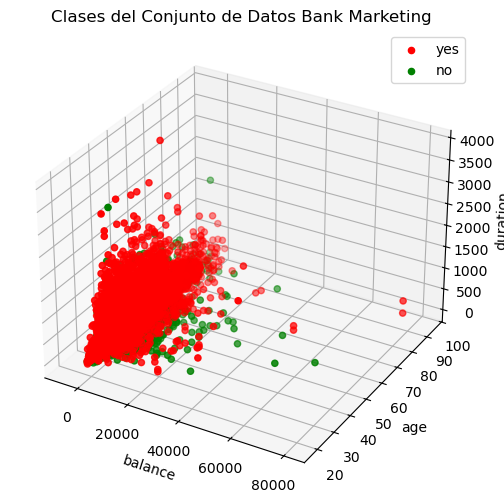

In [94]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

clases = data["deposit"].unique()
colores = ['r', 'g', 'b']

for i, nombre_clase in enumerate(clases):
    indices = np.where(data["deposit"] == nombre_clase)[0]
    ax.scatter(data.iloc[indices, 5],
               data.iloc[indices, 0],
               data.iloc[indices, 11],
               c=colores[i],
               label=nombre_clase,
               marker='o')

ax.set_xlabel(data.columns[5])
ax.set_ylabel(data.columns[0])
ax.set_zlabel(data.columns[11])

plt.title("Clases del Conjunto de Datos Bank Marketing")
ax.legend()
plt.show()

In [95]:
data = data.dropna()
for col in data.select_dtypes(include=['object']).columns:
    if col != 'deposit':
        le = LabelEncoder()
        data[col] = le.fit_transform(data[col])
le_income = LabelEncoder()
data['deposit'] = le_income.fit_transform(data['deposit'])

In [96]:
X, y = data.drop("deposit", axis=1), data["deposit"]
x_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33)

In [97]:
results = {}
matrix_bank_marketing = []

In [98]:
kneighbors.fit(x_train, y_train)
y_pred = kneighbors.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["kneighbors"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_bank_marketing.append(cm)

In [99]:
svc.fit(x_train, y_train)
y_pred = svc.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["svc"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_bank_marketing.append(cm)

In [100]:
linear_svc.fit(x_train, y_train)
y_pred = linear_svc.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["linear_svc"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_bank_marketing.append(cm)

In [101]:
nu_svc = NuSVC(nu=0.1, random_state=RANDOM_STATE)
nu_svc.fit(x_train, y_train)
y_pred = nu_svc.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["nu_svc"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_bank_marketing.append(cm)

In [102]:
decision_tree.fit(x_train, y_train)
y_pred = decision_tree.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["decision_tree"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_bank_marketing.append(cm)

In [103]:
random_forest.fit(x_train, y_train)
y_pred = random_forest.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["random_forest"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_bank_marketing.append(cm)

In [104]:
ada_boost.fit(x_train, y_train)
y_pred = ada_boost.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["ada_boost"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_bank_marketing.append(cm)

In [105]:
gradient_boosting.fit(x_train, y_train)
y_pred = gradient_boosting.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["gradient_boosting"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_bank_marketing.append(cm)

In [106]:
gaussian_nb.fit(x_train, y_train)
y_pred = gaussian_nb.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["gaussian_nb"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_bank_marketing.append(cm)

In [107]:
mlp.fit(x_train, y_train)
y_pred = mlp.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["mlp"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_bank_marketing.append(cm)

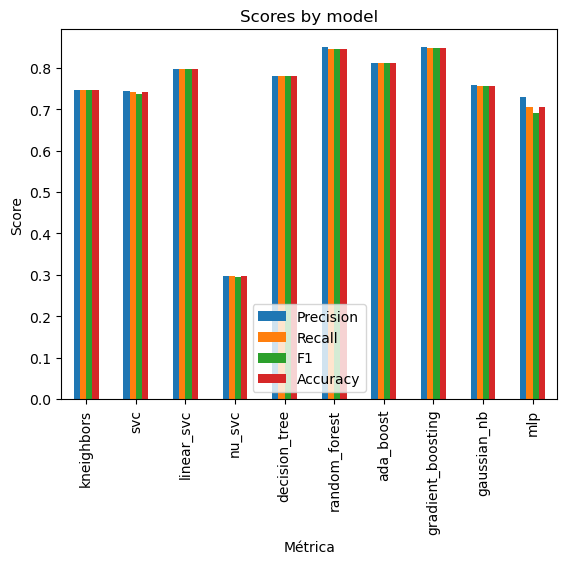

In [108]:
metrics = ["Precision", "Recall", "F1", "Accuracy"]

df = pd.DataFrame.from_dict(results, orient="index" ,columns=metrics)

df.plot(kind="bar")
plt.ylabel("Score")
plt.xlabel("Métrica")
plt.title("Scores by model")
plt.show()

Comparmos las matrices de confusion del dataset Bank_Marketing

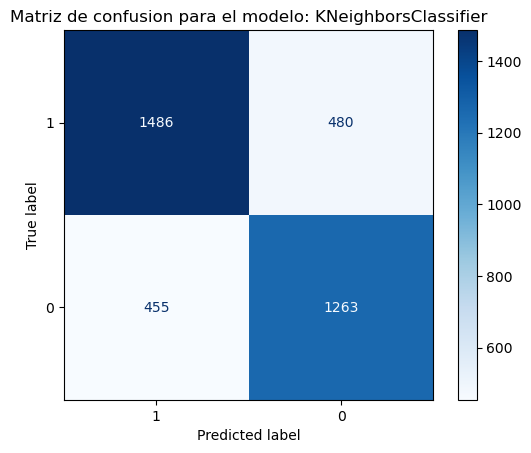

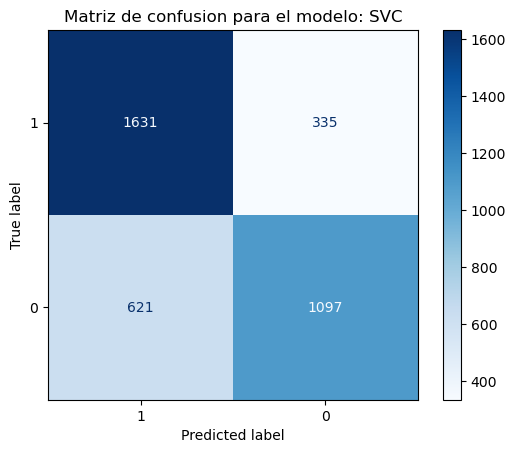

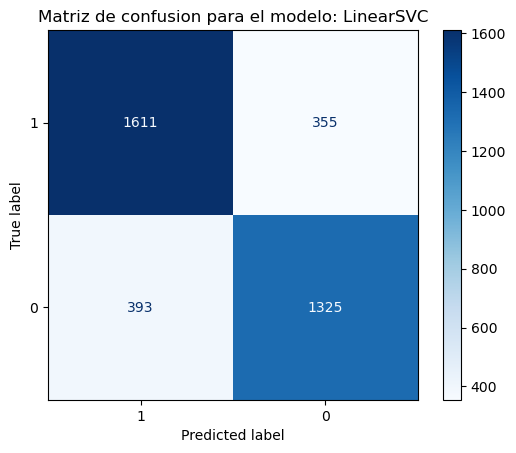

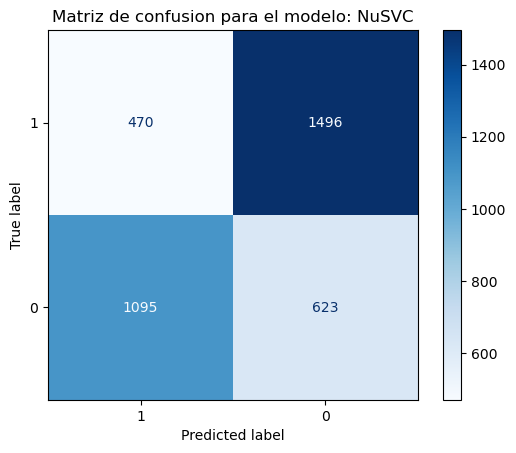

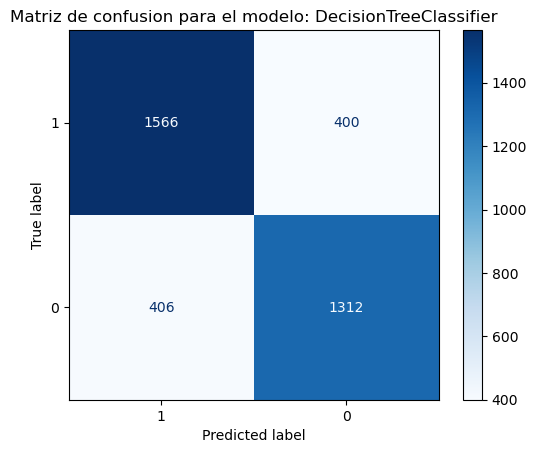

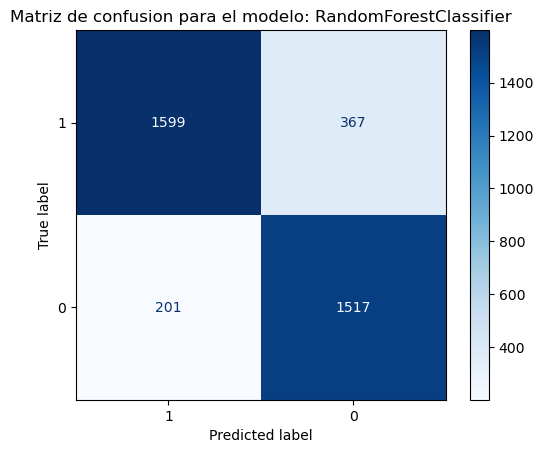

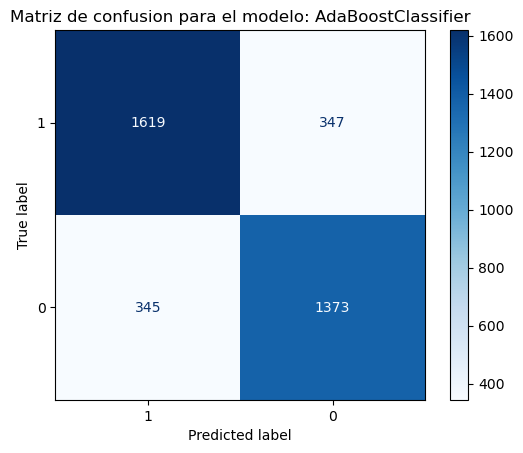

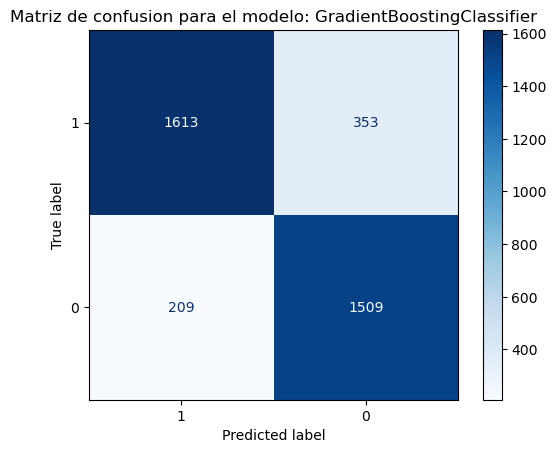

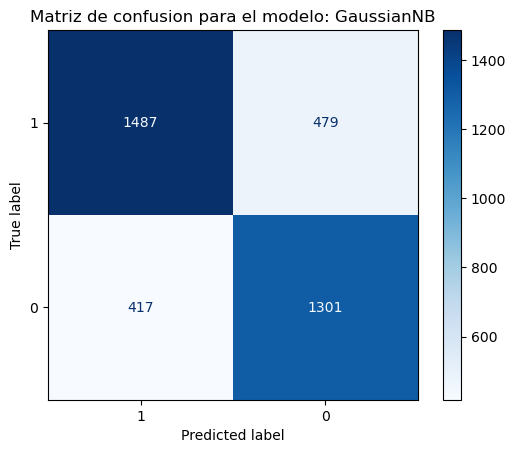

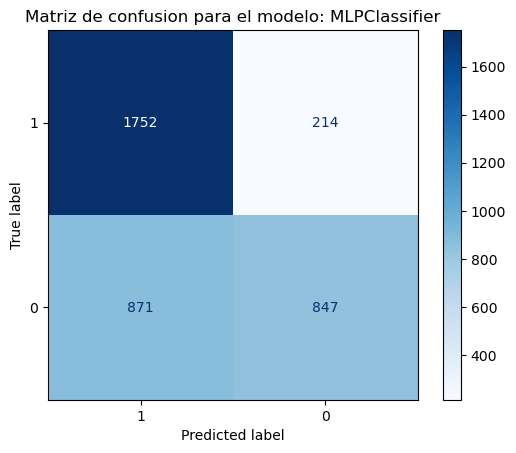

In [109]:
plot_confusion_matrix1(matrix_bank_marketing,y_test.unique())

# Titanic Dataset

In [110]:
path = "https://docs.google.com/spreadsheets/d/e/2PACX-1vSVB1g3exDL38Vr696cRshWN0S4VSVQH8DnUvhF-qirhmFV8TSeueHbsM-7nsKNGc8d6rQfCl6RZQOp/pub?gid=1595571804&single=true&output=csv"
data = pd.read_csv(path)

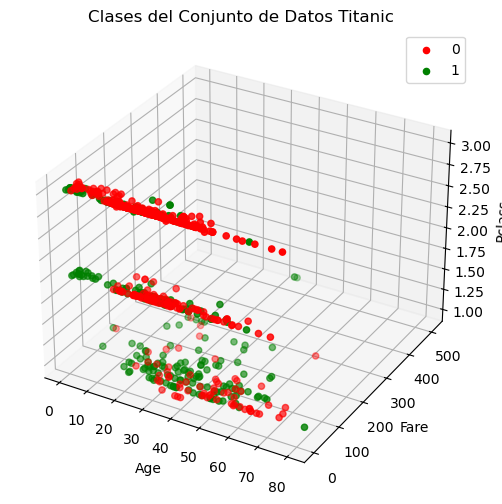

In [111]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

clases = data["Survived"].unique()
colores = ['r', 'g', 'b']

for i, nombre_clase in enumerate(clases):
    indices = np.where(data["Survived"] == nombre_clase)[0]
    ax.scatter(data.iloc[indices, 5],
               data.iloc[indices, 9],
               data.iloc[indices, 2],
               c=colores[i],
               label=nombre_clase,
               marker='o')

ax.set_xlabel(data.columns[5])
ax.set_ylabel(data.columns[9])
ax.set_zlabel(data.columns[2])

plt.title("Clases del Conjunto de Datos Titanic")
ax.legend()
plt.show()

In [112]:
data = data.dropna()
data = data.drop("PassengerId", axis=1)
data = data.drop("Name", axis=1)
for col in data.select_dtypes(include=['object']).columns:
    if col != 'Survived':
        le = LabelEncoder()
        data[col] = le.fit_transform(data[col])
le_income = LabelEncoder()
data['Survived'] = le_income.fit_transform(data['Survived'])

Solo ploteamos los primeros 3 features debido a que no se pueden representar mas dimensiones.

In [113]:
X, y = data.drop("Survived", axis=1), data["Survived"]
x_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33)

In [114]:
results = {}
matrix_titanic = []

In [115]:
kneighbors.fit(x_train, y_train)
y_pred = kneighbors.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["kneighbors"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_titanic.append(cm)

In [116]:
svc.fit(x_train, y_train)
y_pred = svc.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["svc"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_titanic.append(cm)

/opt/anaconda3/envs/mlescom/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/envs/mlescom/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/envs/mlescom/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", res

In [117]:
linear_svc.fit(x_train, y_train)
y_pred = linear_svc.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["linear_svc"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_titanic.append(cm)

In [118]:
nu_svc = NuSVC(nu=0.1, random_state=RANDOM_STATE)
nu_svc.fit(x_train, y_train)
y_pred = nu_svc.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["nu_svc"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_titanic.append(cm)

In [119]:
decision_tree.fit(x_train, y_train)
y_pred = decision_tree.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["decision_tree"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_titanic.append(cm)

In [120]:
random_forest.fit(x_train, y_train)
y_pred = random_forest.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["random_forest"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_titanic.append(cm)

In [121]:
ada_boost.fit(x_train, y_train)
y_pred = ada_boost.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["ada_boost"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_titanic.append(cm)

In [122]:
gradient_boosting.fit(x_train, y_train)
y_pred = gradient_boosting.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["gradient_boosting"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_titanic.append(cm)

In [123]:
gaussian_nb.fit(x_train, y_train)
y_pred = gaussian_nb.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["gaussian_nb"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_titanic.append(cm)

In [124]:
mlp.fit(x_train, y_train)
y_pred = mlp.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["mlp"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_titanic.append(cm)

/opt/anaconda3/envs/mlescom/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


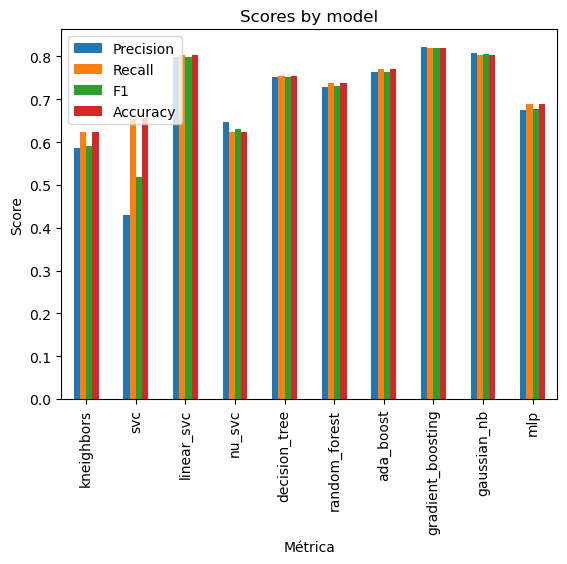

In [125]:
metrics = ["Precision", "Recall", "F1", "Accuracy"]

df = pd.DataFrame.from_dict(results, orient="index" ,columns=metrics)

df.plot(kind="bar")
plt.ylabel("Score")
plt.xlabel("Métrica")
plt.title("Scores by model")
plt.show()

Se comparan las matrices de confusion del dataset de Titanic

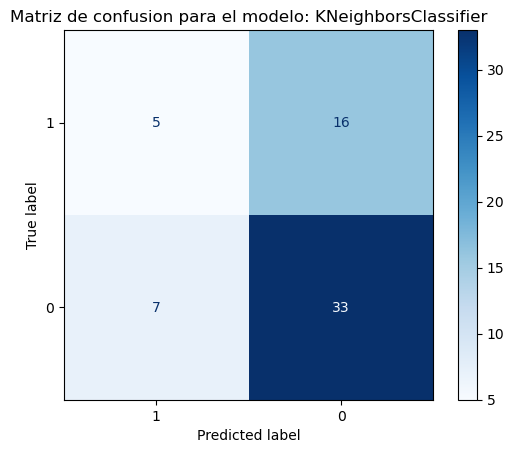

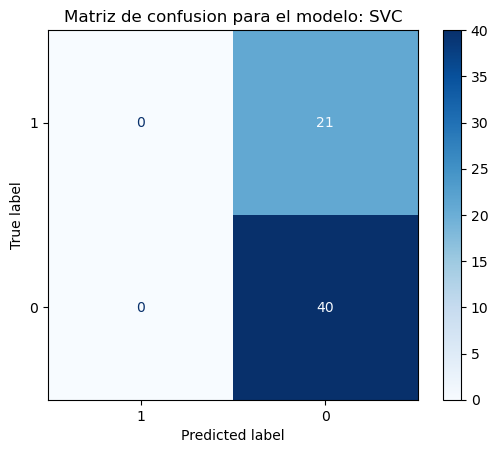

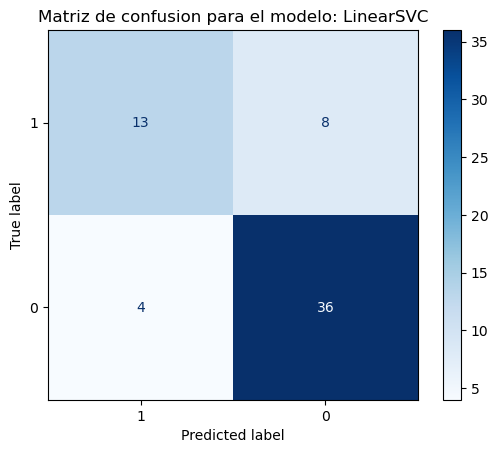

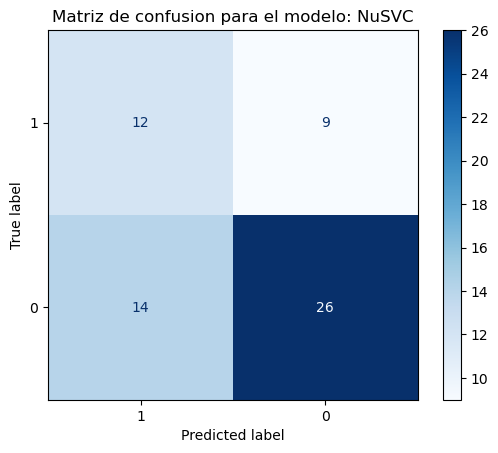

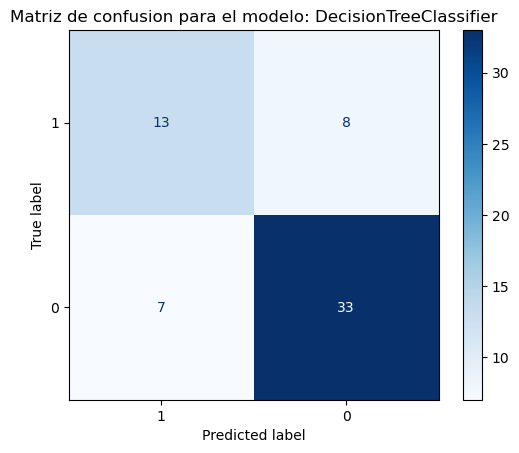

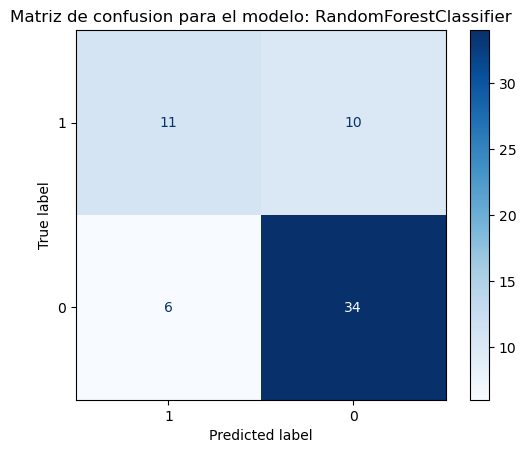

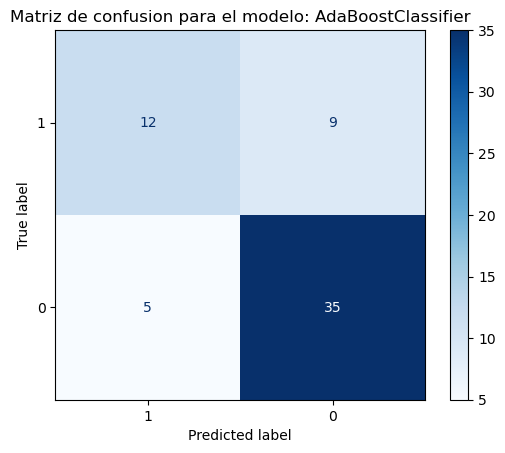

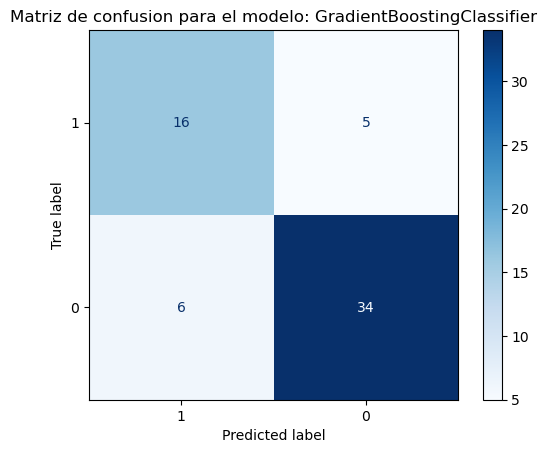

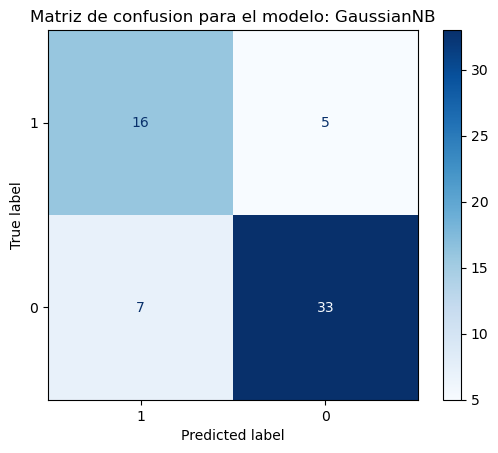

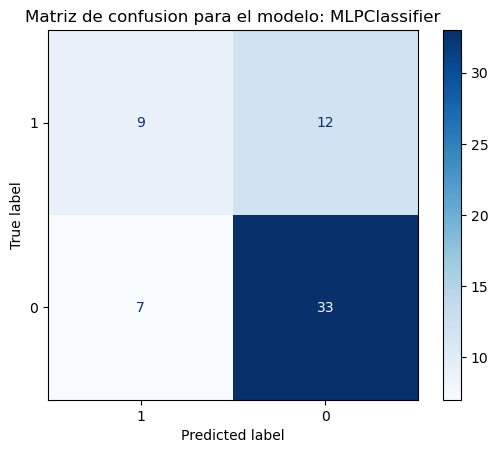

In [126]:
plot_confusion_matrix1(matrix_titanic,y_test.unique())

# Mnist Handwritten Digits

In [6]:
def read_idx(filename):
    with open(filename, 'rb') as f:
        data = np.frombuffer(f.read(), dtype=np.uint8)
        if 'images' in filename:
            return data[16:].reshape(-1, 28, 28)
        else:
            return data[8:]

In [7]:
from google.colab import drive
drive.mount('/content/drive')

ModuleNotFoundError: No module named 'google'

In [8]:

train_images = '/content/drive/MyDrive/archive/train-images.idx3-ubyte'
train_labels = '/content/drive/MyDrive/archive/train-labels.idx1-ubyte'
test_images = '/content/drive/MyDrive/archive/t10k-images.idx3-ubyte'
test_labels = '/content/drive/MyDrive/archive/t10k-labels.idx1-ubyte'

x_train = read_idx(train_images)[:1000]
y_train = read_idx(train_labels)[:1000]
X_test = read_idx(test_images)[:200]
y_test = read_idx(test_labels)[:200]

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/archive/train-images.idx3-ubyte'

In [9]:
x_train.shape

NameError: name 'x_train' is not defined

NameError: name 'x_train' is not defined

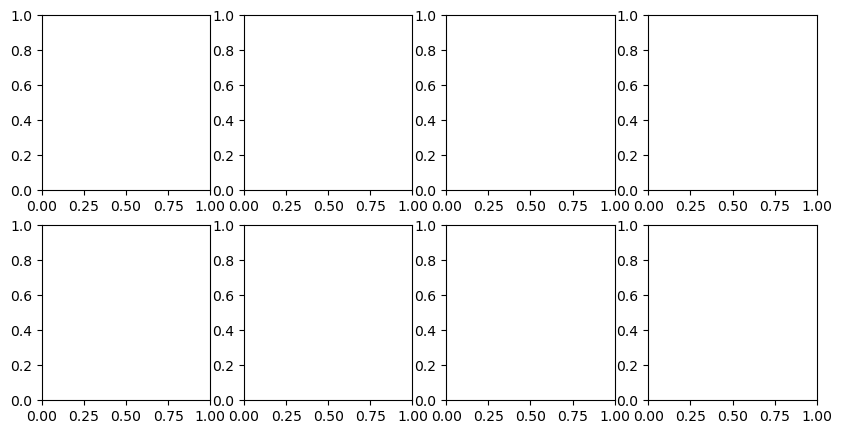

In [10]:
indices = [0, 10, 20, 30, 40, 50, 60, 70]
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
axes = axes.ravel()

for i, ax in enumerate(axes):
    if i < len(indices):
        image = x_train[indices[i]]
        ax.imshow(image, cmap=plt.cm.gray_r, interpolation='nearest')
        ax.set_title(f'Label: {y_train[indices[i]]}')
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()

In [11]:
results = {}
matrix_handwritten = []

In [ ]:
x_train = x_train.reshape(x_train.shape[0], -1)
X_test = X_test.reshape(X_test.shape[0], -1)

In [ ]:
kneighbors.fit(x_train, y_train)
y_pred = kneighbors.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["kneighbors"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_handwritten.append(cm)

In [ ]:
svc.fit(x_train, y_train)
y_pred = svc.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["svc"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_handwritten.append(cm)

In [ ]:
linear_svc.fit(x_train, y_train)
y_pred = linear_svc.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["linear_svc"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_handwritten.append(cm)

In [ ]:
nu_svc = NuSVC(nu=0.1, random_state=RANDOM_STATE)
nu_svc.fit(x_train, y_train)
y_pred = nu_svc.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["nu_svc"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_handwritten.append(cm)

In [ ]:
decision_tree.fit(x_train, y_train)
y_pred = decision_tree.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["decision_tree"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_handwritten.append(cm)

In [ ]:
random_forest.fit(x_train, y_train)
y_pred = random_forest.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["random_forest"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_handwritten.append(cm)

In [ ]:
ada_boost.fit(x_train, y_train)
y_pred = ada_boost.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["ada_boost"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_handwritten.append(cm)

In [ ]:
gradient_boosting.fit(x_train, y_train)
y_pred = gradient_boosting.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["gradient_boosting"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_handwritten.append(cm)

In [ ]:
gaussian_nb.fit(x_train, y_train)
y_pred = gaussian_nb.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["gaussian_nb"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_handwritten.append(cm)

In [ ]:
mlp.fit(x_train, y_train)
y_pred = mlp.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["mlp"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_handwritten.append(cm)

In [ ]:
metrics = ["F1","Accuracy", "Precision","Recall"]

df = pd.DataFrame.from_dict(results, orient="index" ,columns=metrics)

df.plot(kind="bar")
plt.ylabel("Score")
plt.xlabel("Métrica")
plt.title("Scores by model")
plt.show()

Se comparan las matrices de confusion del dataset Mnist Handwritten Digits

In [ ]:
plot_confusion_matrix1(matrix_handwritten, np.unique(y_test))

# Spam vs Ham Email

Funcion para limpiar la informacion


In [12]:
def clean_text(text):
    text = text.lower() # Convertir a minúsculas
    # Eliminar puntuación usando expresión regular
    text = re.sub(f'[{re.escape(string.punctuation)}]', '', text)
    return text


Importamos el dataset

In [13]:
path = "https://docs.google.com/spreadsheets/d/e/2PACX-1vTNzEBShvOPnOaW9GSVPrDA8gPg-sl6PeH1PlXvNaHFhN84mctZmDdZL4RaqEC8tweeOIJ9V5TQdhTu/pub?output=csv"
data = pd.read_csv(path)

Normalizamos la informacion

In [14]:
data['text'] = data['text'].apply(clean_text)

X_text = data['text']
y = data['label_num']

tfidf_vectorizer = TfidfVectorizer(stop_words='english', min_df=5)

x_train_text, X_test_text, y_train, y_test = train_test_split(X_text, y, test_size=0.2, random_state=42, stratify=y)

x_train = tfidf_vectorizer.fit_transform(x_train_text)
X_test = tfidf_vectorizer.transform(X_test_text)

data

,Unnamed: 0,label,text,label_num
0,605,ham,subject enron methanol meter 988291\nthis i...,0
1,2349,ham,subject hpl nom for january 9 2001\n see atta...,0
2,3624,ham,subject neon retreat\nho ho ho we re around ...,0
3,4685,spam,subject photoshop windows office cheap mai...,1
4,2030,ham,subject re indian springs\nthis deal is to bo...,0
...,...,...,...,...
5166,1518,ham,subject put the 10 on the ft\nthe transport vo...,0
5167,404,ham,subject 3 4 2000 and following noms\nhpl can...,0
5168,2933,ham,subject calpine daily gas nomination\n\n\njuli...,0
5169,1409,ham,subject industrial worksheets for august 2000 ...,0


In [15]:
results = {}
matrix_spam = []

In [16]:
kneighbors.fit(x_train, y_train)
y_pred = kneighbors.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["kneighbors"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_spam.append(cm)

In [17]:
svc.fit(x_train, y_train)
y_pred = svc.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred,output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["svc"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_spam.append(cm)

In [18]:
linear_svc.fit(x_train, y_train)
y_pred = linear_svc.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["linear_svc"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_spam.append(cm)

In [19]:
nu_svc = NuSVC(nu=0.1,random_state = RANDOM_STATE)
nu_svc.fit(x_train, y_train)
y_pred = nu_svc.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["nu_svc"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_spam.append(cm)


In [20]:
decision_tree.fit(x_train, y_train)
y_pred = decision_tree.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["decision_tree"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_spam.append(cm)

In [21]:
random_forest.fit(x_train, y_train)
y_pred = random_forest.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["random_forest"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test,y_pred)
matrix_spam.append(cm)

In [22]:
ada_boost.fit(x_train, y_train)
y_pred = ada_boost.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred,output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["ada_boost"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_spam.append(cm)

In [23]:
gradient_boosting.fit(x_train,y_train)
y_pred = gradient_boosting.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["gradient_boosting"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_spam.append(cm)

In [24]:
gaussian_nb.fit(x_train.toarray(),y_train)
y_pred = gaussian_nb.predict(X_test.toarray())
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["gaussian_nb"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_spam.append(cm)

In [25]:
mlp.fit(x_train, y_train)
y_pred = mlp.predict(X_test)
report = classification_report(y_test, y_pred)
report_dict = classification_report(y_test, y_pred, output_dict=True)
weighted_avg = report_dict["weighted avg"]
results["mlp"] = [weighted_avg["precision"], weighted_avg["recall"], weighted_avg["f1-score"], report_dict["accuracy"]]
cm = confusion_matrix(y_test, y_pred)
matrix_spam.append(cm)

Graficamos las diferencias entre cada modelo

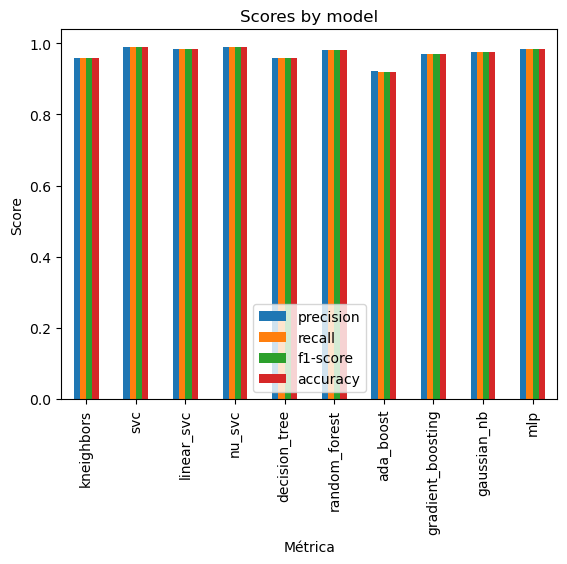

In [26]:
metrics = ['precision','recall','f1-score','accuracy']

df = pd.DataFrame.from_dict(results, orient="index" ,columns=metrics)

df.plot(kind="bar")
plt.ylabel("Score")
plt.xlabel("Métrica")
plt.title("Scores by model")
plt.show()

Comparamos las matrices de confusion de todos los modelos

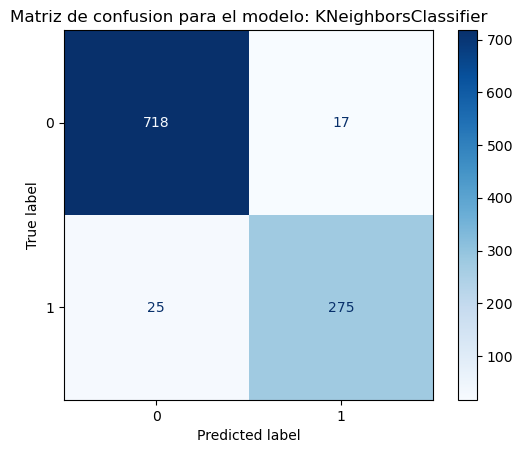

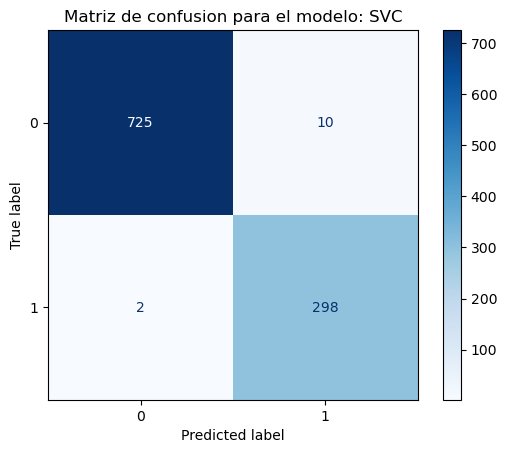

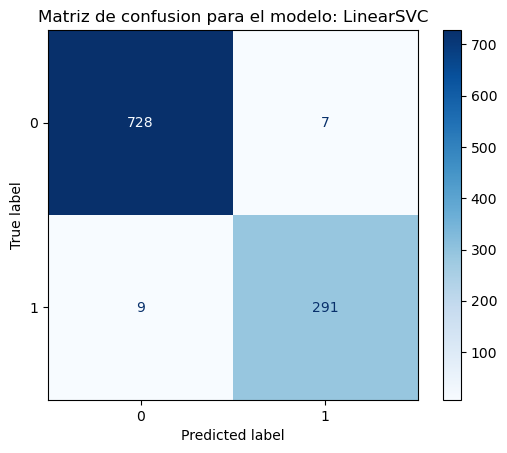

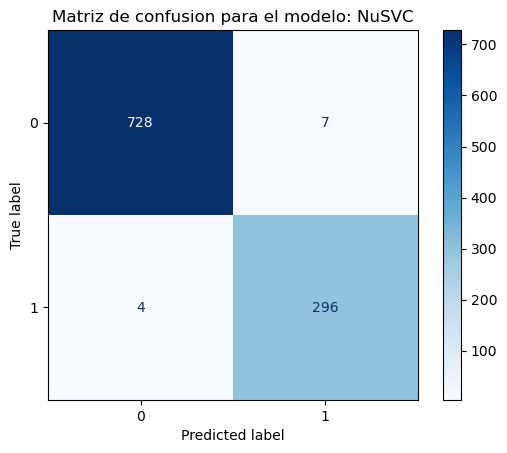

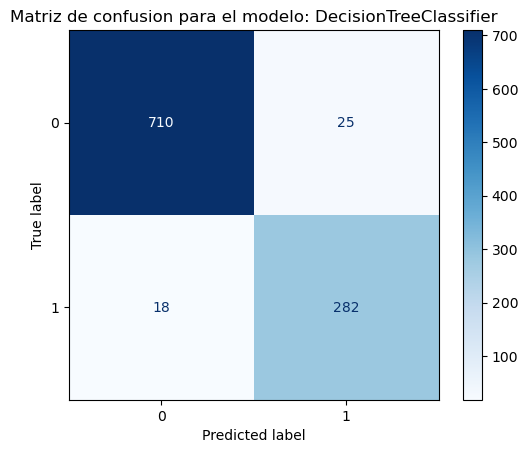

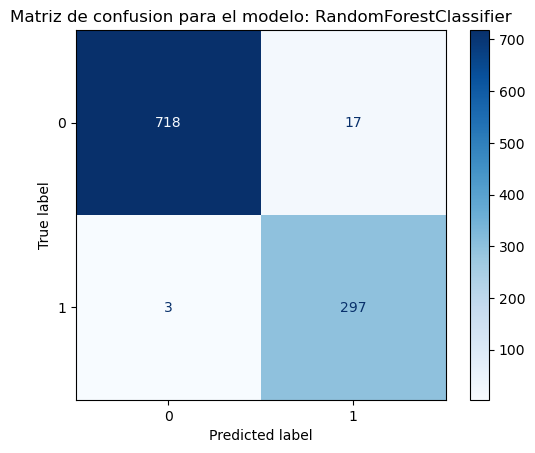

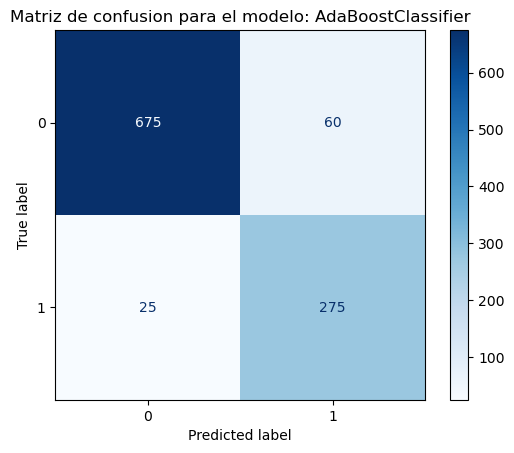

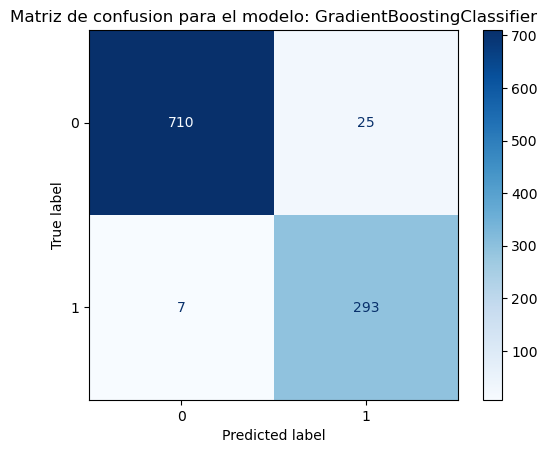

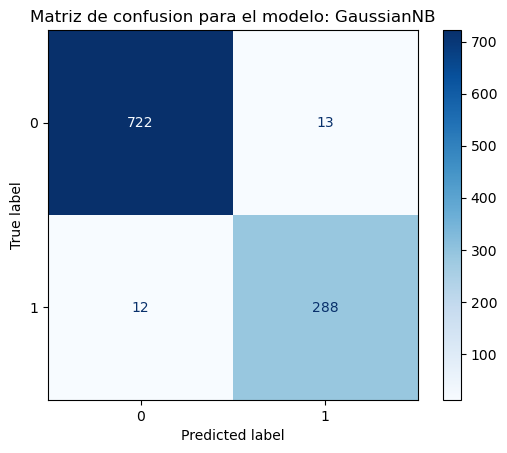

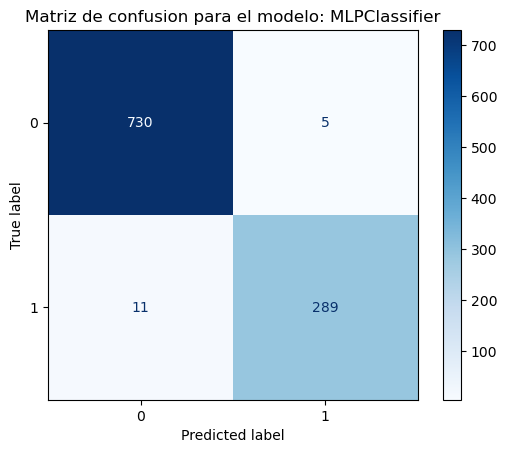

In [27]:
plot_confusion_matrix1(matrix_spam, np.unique(y_test))
